# Can an LLM plan a day's pickups?

A driver collecting freight from local shops starts with an empty van. At each address, the driver checks in, waits if the load is still being prepared, and takes on a little more weight. By the last stop, there has to be room for one more load and time to get the whole day's freight back to the depot. A useful plan tells each driver where to go, in what order and when to leave. Dispatch can send it out with confidence that every booked pickup fits.

The consequences show up at individual stops. If a truck gets to a dock just as it closes, the loading crew has gone home. If it arrives half an hour early, the driver may wait with the truck loaded. Distance still matters, because extra kilometres cost time and money. A dispatcher has to compare distance, wait time and equipment across the day, with the rest of the fleet already assigned to work of its own.

### Illustrative example of a dock closing at noon

Suppose a dispatcher has one dry van and one refrigerated van. Two shops have cartons ready any time this morning. A grocery dock has chilled cases ready at 11 and closes at noon. The driver needs 15 minutes to load the cases, so service has to start by 11:45. The first part of the plan is to give the grocery pickup to the refrigerated van.

The grocery dock is close to both shops on a map. Say the refrigerated van could reach the dock at 11:30 going straight there. A stop at one shop takes 10 minutes of extra driving and 10 minutes to load. That moves the grocery arrival to 11:50. Loading ends at 12:05, five minutes after close. The dry van could take the shop instead, or the refrigerated van could collect the chilled cases first if the equipment and freight allow it.

Now suppose the grocery dock tells dispatch it will close at 11:50 and one driver is already on the way to a shop. The morning plan is partly carried out. A revised plan has to preserve the trip already underway, use the vans from where they are, and account for what each one is carrying. A good answer can mean giving the dry van one or two new stops while keeping most of its list intact.

A route optimizer works with those limits as rules. It evaluates choices such as adding a stop after another stop, trading stops between two vehicles or changing a departure time. It keeps track of the best complete plan it has found. A language model can also read the manifest, group nearby pickups and write a stop list. Seeing the geography may help it choose groups. With an optimizer available, its draft can provide a first plan for the optimizer to improve, provided the draft is usable.

We call a plan **dispatchable** when every pending pickup is assigned exactly once and all the modeled operating rules hold. That is the first measure. A plan that serves 239 of 240 pickups can teach us a lot about where the method breaks, while dispatch still needs a route for the remaining pickup. We compare operating costs between plans on days when both pass.

## Question

On 24 simulated Toronto dispatch days, each with **24 vehicles and 240 pickups at real commercial addresses**, can GPT-6 Luna, GPT-6.1 Terra or GPT-6.2 Sol plan the day's work and handle an 11 a.m. disruption? How often does a labeled street map help, and does starting from either model's draft improve on a conventional optimizer working under the same deadline?

## Study in brief

**At the full fleet scale, the models produced 0 dispatchable morning plans in 144 attempts.** 45 of those attempts gave a readable route list. At 11 a.m. the pending workload dropped to 96–98 pickups. The models produced 5 dispatchable replans in 144 attempts (Luna 0 without a map and 0 with one, Terra 2 without a map and 3 with one, Sol 0 without a map and 0 with one). Sol timed out on 96/96 fleet sessions. Every model and map condition was tested on the same 24 days.

The configured unseeded optimizer passed 15/24 mornings and 11/24 replans. Giving it a simple insertion plan when one was available gave 15/24 and 15/24. Across the LLM arms, 5 drafts were accepted as solver starts and 1/96 jointly feasible pairs beat the unseeded solver's operating cost. These results depend on the solver's method of finding a first plan. One failed search does not imply the workload was infeasible.

The strongest small-scope result came when each truck already had its jobs. Across 72 model attempts, 59 single-truck orders matched the exact minimum. In a separate replan check, moving the three affected appointments within the existing driver lists repaired 24/24 days. The jobs and incidents are simulated. Both follow-ups benefit from knowing where the work was assigned before the disruption.

## Contents

1. [Data and the dispatch day](#1-data-and-the-dispatch-day)
2. [Planners and comparison](#2-planners-and-comparison)
3. [Checking a plan](#3-checking-a-plan)
4. [Morning and 11 a.m. results](#4-morning-and-11-am-results)
5. [Reading the plans that passed and failed](#5-reading-the-plans-that-passed-and-failed)
6. [Sequencing one truck in one part of the day](#6-sequencing-one-truck-in-one-part-of-the-day)
7. [Limitations](#7-limitations)
8. [How to reproduce](#8-how-to-reproduce)
9. [Future work and further reading](#9-future-work-and-further-reading)

```mermaid
flowchart LR
    G["241 real locations<br/>Two vehicle road matrices"] --> D["24 frozen operating days<br/>240 pickups and 24 vehicles each"]
    D --> M["Morning manifest<br/>240 pickup jobs"]
    D --> P["Replay a shared morning plan to 11 a.m.<br/>96 to 98 pending pickups"]
    M --> C["3 models × text or map<br/>144 morning sessions"]
    P --> E["3 models × text or map<br/>144 replan sessions"]
    C --> R["Independent route replay<br/>Score draft and solver-assisted route"]
    E --> R
    D --> A["Deterministic dispatch baselines<br/>48 day-stage states"]
    A --> R
    R --> O["Feasible days, operating costs,<br/>and changes to driver lists"]
    D --> B["24 fixed truck blocks<br/>72 sequencing sessions"]
    B --> X["Exact permutation check<br/>Feasibility and minimum cost"]
```

A day enters the morning comparison with 240 jobs and a new fleet sheet. A separate replay starts every 11 a.m. planner from the same operating state, leaving 96–98 jobs to assign. For example, day D01 starts with the same pickup addresses in both columns. The afternoon view removes completed or committed work and moves the affected deadlines. Every returned whole-fleet plan is checked against the same stage records.

## Setup

This code names the inputs and fixes the default replay behavior. Every replay uses the frozen map images, the checked Toronto road files and the original replies. The optional local solver run investigates timing on one day.

In [1]:
N_DAYS = 24
ALLOW_FRESH_MODEL_CALLS = False
FRESH_DAY_LIMIT = 2
RERUN_FIRST_SOLVER_CASE = False

import shutil
from IPython.display import Image, display

from copy import deepcopy
from pathlib import Path
import gzip
import json
import math
import random

import numpy as np


DATA = Path("data")
REPLAN_MINUTE = 11 * 60
PILOT = [["P01", "ordinary", 680153, 24], ["P02", "tight windows", 680251, 24]]
HELD_OUT = [
    [f"D{i + 1:02}", ["ordinary", "tight windows", "scarce specialist capacity"][i // 8],
     701347 + i * 1723, 240]
    for i in range(24)
]
KINDS = {
    "dry": {"profile": 0, "caps": [1080, 10200, 0], "fixed": 2400, "km": 37, "minute": 55},
    "chill": {"profile": 0, "caps": [880, 7600, 0], "fixed": 3900, "km": 57, "minute": 63},
    "lift": {"profile": 1, "caps": [2250, 22000, 8], "fixed": 5400, "km": 83, "minute": 71},
}


def minute_name(value):
    return f"{value // 60:02}:{value % 60:02}"


def leg_minutes(seconds, profile, start, end):
    duration = int(seconds[profile, start, end])
    if duration < 0:
        raise ValueError(f"Unreachable road leg {start} to {end} for profile {profile}")
    return (duration + 59) // 60


def split_total(rng, total, count, minimum, spread):
    weights = [rng.uniform(1 - spread, 1 + spread) for _ in range(count)]
    denominator = sum(weights)
    extra = total - minimum * count
    values = [minimum + int(extra * weight / denominator) for weight in weights]
    for i in range(total - sum(values)):
        values[i] += 1
    return values


def create_vehicle(rng, number, kind):
    return {
        **deepcopy(KINDS[kind]),
        "id": f"V{number:02}",
        "kind": kind,
        "position": 0,
        "ready": rng.choice([7 * 60 + 45, 8 * 60, 8 * 60 + 15]),
        "close": rng.choice([16 * 60, 16 * 60 + 15, 16 * 60 + 30]),
        "load": [0, 0, 0],
        "active": False,
    }


def ordered_by_drive(indices, origin, profile, seconds):
    order = []
    unvisited = set(indices)
    while unvisited:
        current = min(unvisited, key=lambda j: (leg_minutes(seconds, profile, origin, j), j))
        unvisited.remove(current)
        order.append(current)
        origin = current
    return order


def choose_sites(rng, indices, geography):
    # The dock routes favor the municipal warehouse subset. Some storefronts
    # can take small pallets curbside in the fictional operation.
    pool = list(indices)
    lift_count = len(pool) // 4
    lift = sorted(
        pool,
        key=lambda j: (
            rng.random() - (0.85 if "warehouse" in geography[j]["kind"].lower() else 0),
            j,
        ),
    )[:lift_count]
    pool = [j for j in pool if j not in lift]
    chill = sorted(
        pool,
        key=lambda j: (
            rng.random() + (0.8 if "warehouse" in geography[j]["kind"].lower() else 0),
            j,
        ),
    )[:lift_count]
    dry = sorted((j for j in pool if j not in chill), key=lambda j: geography[j]["lat"])
    return [("dry", dry[:lift_count]), ("dry", dry[lift_count:]), ("chill", chill), ("lift", lift)]


def build_morning(rng, seed, n, stratum, geography, seconds):
    angle = rng.uniform(-0.58, 0.58)
    indices = list(range(1, 241))
    if n < 240:
        center_lon = rng.choice([-79.48, -79.43, -79.39, -79.33])
        nearest = sorted(indices, key=lambda j: abs(geography[j]["lon"] - center_lon))[:2 * n]
        indices = rng.sample(nearest, n)
    ordering = sorted(
        indices,
        key=lambda j: (
            (geography[j]["lon"] + 79.4) * math.cos(angle) * 0.72
            + (geography[j]["lat"] - 43.7) * math.sin(angle)
            + rng.uniform(-0.019, 0.019)
        ),
    )
    territory_size = 40 if n == 240 else n
    stops, vehicles, reference = {}, [], {}
    for start in range(0, n, territory_size):
        for kind, indices in choose_sites(rng, ordering[start:start + territory_size], geography):
            vehicle = create_vehicle(rng, len(vehicles) + 1, kind)
            profile, count = vehicle["profile"], len(indices)
            vehicles.append(vehicle)
            # Similar stop count, variable load class and capacity utilization.
            fraction = rng.uniform(0.61, 0.80)
            if stratum == "scarce specialist capacity" and kind != "dry":
                fraction = rng.uniform(0.88, 0.96)
            kg = split_total(rng, int(vehicle["caps"][0] * fraction), count, 16, 0.65)
            litres = split_total(rng, int(vehicle["caps"][1] * fraction), count, 180, 0.70)
            pallet_count = min(count, rng.choice([5, 6, 7])) if kind == "lift" else 0
            if kind == "lift" and stratum == "scarce specialist capacity":
                pallet_count = min(count, 8)
            pallet_sites = set(rng.sample(indices, pallet_count))
            for j, weight, volume in zip(indices, kg, litres):
                pallet = int(j in pallet_sites)
                if pallet:
                    warehouse = "warehouse" in geography[j]["kind"].lower()
                    commodity = "dock pallet" if warehouse else "liftgate pallet"
                    allowed, service = ["lift"], rng.randint(12, 20)
                elif kind == "chill":
                    commodity = "chilled cases"
                    allowed, service = ["chill"], rng.randint(7, 13)
                else:
                    curb = kind == "dry" and rng.random() < 0.18
                    commodity = "dry totes, van access" if curb else "dry cartons and totes"
                    allowed = ["dry"] if curb else ["dry", "lift"]
                    service = rng.randint(6, 12)
                stops[j] = {
                    "service": service, "load": [weight, volume, pallet],
                    "allowed": allowed, "commodity": commodity,
                }
            rng.shuffle(indices)
            pivot = count // 2
            early = ordered_by_drive(indices[:pivot], 0, profile, seconds)
            late = ordered_by_drive(indices[pivot:], early[-1], profile, seconds)
            after_lunch = rng.randint(698, 750)
            # Dispatch starts are staggered and one wave is held for afternoon readiness.
            depart = vehicle["ready"] + rng.choice([0, 10, 20])
            clock, location = depart, 0
            for step, j in enumerate(early + late):
                stop = stops[j]
                arrival = clock + leg_minutes(seconds, profile, location, j)
                phase_open = after_lunch if step >= pivot else 8 * 60
                on_site = max(arrival, phase_open)
                clock = on_site + stop["service"]
                location = j
                tolerance = rng.randint(13, 33) if stratum == "tight windows" else rng.randint(32, 97)
                # Most docks open for a service period rather than a point on the witness.
                opening = max(phase_open, on_site - rng.randint(22, 110))
                closing = min(16 * 60, clock + tolerance)
                stop.update(lo=opening, hi=closing)
            reference[vehicle["id"]] = [depart, *(early + late)]
    shuffled = list(range(1, n + 1))
    random.Random(seed ^ 85231).shuffle(shuffled)
    labels = {0: 0, **dict(zip(sorted(stops), shuffled))}
    return stops, vehicles, reference, labels


def replay_to_11(stops, vehicles, routes, morning):
    remaining = set(stops)
    states, locked, completed, undisturbed = [], [], [], {}
    for v in vehicles:
        truck = deepcopy(v)
        vehicle_id = v["id"]
        run = routes[vehicle_id]
        at, ready, load = 0, REPLAN_MINUTE, [0, 0, 0]
        committed = []
        previous_end = run["departure"]
        for row in run["stops"]:
            stop = row["stop"]
            if row["end"] <= REPLAN_MINUTE:
                at, load = stop, row["load"]
                completed.append(stop)
            elif previous_end < REPLAN_MINUTE:
                # The driver has departed toward this visit or is already at the site.
                # Preserve the visit and resume at its actual end with the load onboard.
                locked.append({
                    "vehicle": vehicle_id, "from": at, "stop": stop,
                    "arrive": row["arrival"], "done": row["end"], "load": row["load"],
                })
                at, ready, load = stop, row["end"], row["load"]
                committed.append(stop)
            else:
                break
            previous_end = row["end"]
        remaining.difference_update(completed)
        remaining.difference_update(committed)
        truck.update(position=at, ready=ready, load=load, active=run["departure"] <= REPLAN_MINUTE)
        if run["return"] <= REPLAN_MINUTE:
            truck.update(position=0, load=[0, 0, 0])
        undisturbed[vehicle_id] = [ready, *[j for j in morning[vehicle_id][1:] if j in remaining]]
        states.append(truck)
    return {j: stops[j].copy() for j in sorted(remaining)}, states, locked, completed, undisturbed


def new_events(stops, vehicles, reference, seconds, meters, rng):
    # Find three stops where a genuine sequence change can satisfy an earlier
    # deadline. Each affects a different route in the shared morning plan.
    alternatives, events = deepcopy(reference), []
    trucks = list(vehicles)
    rng.shuffle(trucks)
    titles = ["dock closed early", "expedited pickup", "expedited pickup"]
    for v in trucks:
        vehicle = v["id"]
        depart, *original = reference[vehicle]
        if len(original) < 2:
            continue
        local_stops = {j: stops[j] for j in original}
        baseline = evaluate(local_stops, [v], seconds, meters, {vehicle: reference[vehicle]}, details=True)
        if not baseline["feasible"]:
            raise ValueError(f"Invalid unchanged suffix for {vehicle}: {baseline['violations']}")
        baseline_times = {row["stop"]: row["end"] for row in baseline["routes"][vehicle]["stops"]}
        candidates = list(range(1, len(original)))
        rng.shuffle(candidates)
        for index in candidates:
            picked = original[index]
            sequence = [picked, *original[:index], *original[index + 1:]]
            alternate = [depart, *sequence]
            scored = evaluate(local_stops, [v], seconds, meters, {vehicle: alternate}, details=True)
            if not scored["feasible"]:
                continue
            done = scored["routes"][vehicle]["stops"][0]["end"]
            if baseline_times[picked] - done < 10:
                continue
            old_hi = stops[picked]["hi"]
            new_hi = min(old_hi, (done + baseline_times[picked]) // 2)
            stops[picked].update(hi=new_hi, urgent=True, incident=titles[len(events)])
            events.append({
                "kind": titles[len(events)], "stop": picked,
                "old_hi": old_hi, "new_hi": new_hi, "former_end": baseline_times[picked],
                "witness_end": done,
            })
            alternatives[vehicle] = alternate
            break
        if len(events) == 3:
            return events, alternatives
    return [], {}


def make_case(spec, geography, seconds, meters):
    item, stratum, seed, n = spec
    for attempt in range(120):
        rng = random.Random(seed + attempt * 10109)
        try:
            stops, vehicles, morning, labels = build_morning(rng, seed, n, stratum, geography, seconds)
            scored = evaluate(stops, vehicles, seconds, meters, morning, details=True)
            if not scored["feasible"]:
                continue
            remaining, states, locked, completed, undisturbed = replay_to_11(
                stops, vehicles, scored["routes"], morning
            )
            before = evaluate(remaining, states, seconds, meters, undisturbed)
            if not before["feasible"]:
                continue
            events, completion = new_events(remaining, states, undisturbed, seconds, meters, rng)
            if not events or not evaluate(remaining, states, seconds, meters, completion)["feasible"]:
                continue
            assert len(stops) == len(completed) + len(locked) + len(remaining)
            assert len({event["stop"] for event in events}) == 3
            return {
                "id": item, "stratum": stratum, "seed": seed, "candidate_rejections": attempt,
                "labels": labels,
                "morning": {"stops": stops, "vehicles": vehicles, "witness": morning},
                "replan": {"stops": remaining, "vehicles": states, "witness": completion,
                           "events": events, "locked": locked, "completed": completed,
                           "unchanged": undisturbed, "unchanged_minutes": before["minutes"]},
            }
        except ValueError as error:
            if "Unreachable road leg" not in str(error):
                raise
    raise RuntimeError(f"No feasible witness pair for {item} after 120 fixture attempts")


def write_json_gz(path, value):
    path = Path(path)
    payload = json.dumps(value, ensure_ascii=False, separators=(",", ":")).encode("utf-8")
    path.write_bytes(gzip.compress(payload, compresslevel=6, mtime=0))


def read_json_gz(path):
    return json.loads(gzip.decompress(Path(path).read_bytes()))


def load_frozen_cases(path):
    cases = read_json_gz(path)
    for case in cases:
        case["labels"] = {int(i): label for i, label in case["labels"].items()}
        for name in ("morning", "replan"):
            case[name]["stops"] = {int(i): stop for i, stop in case[name]["stops"].items()}
    return cases

## 1. Data and the dispatch day

The depot is the Ontario Food Terminal at 165 The Queensway. The addresses in the manifest cover 192 food premises such as grocers, bakeries and restaurants, plus 48 municipal address points inside buildings tagged industrial or warehouse. Street locations are real. The pickups and the carrier are fictional. A point on a map can locate an address, while its loading time, size of shipment and available equipment come from the experiment. The same address panel represents recurring customers across the 24 days. Every day draws new load quantities, time windows, shifts and vehicle assignments. [Geography sources and licences](data/geography_sources.md)

We use two different models of driving. A cargo van uses a standard road profile. The box truck is modeled at 3.35 m high, 2.55 m wide and 6.58 t gross weight, with a truck profile that checks mapped truck restrictions. Both use paths on the same pinned OpenStreetMap snapshot. The driving time from one address to another is allowed to differ in the reverse direction. One-way streets and the direction of turns can change which path is available. Each route leg rounds the travel time up to a whole minute. That way an estimated drive of 8 minutes and 2 seconds occupies 9 minutes in the schedule.

Across 57,840 directed pairs of different locations, the truck and van travel times differ on 23,698 pairs. The truck time is higher on 14,430 of those and lower on 9,268, with a median absolute difference of 31 seconds. One long discrepancy is the leg from **2795 Danforth Avenue to 1468 Queen Street West**. The van path is 15.578 km and takes 24 minutes 38 seconds. The truck path is 23.125 km and takes 33 minutes 56 seconds. That leg uses 25 minutes in the van timetable and 34 in the truck timetable. The routes can differ even though the pins on either map sit in the same places. This is why everybody gets road times in addition to coordinates. [Valhalla routing profiles](https://valhalla.github.io/valhalla/api/turn-by-turn/api-reference/)

| Vehicles per day | Configuration | Simulated freight and access | Simulated usable capacity |
| --- | --- | --- | --- |
| 12 dry cargo vans | Ford Transit configuration | Dry cartons and totes. Some sites have van-only access. | 1,080 kg and 10,200 L |
| 6 refrigerated vans | Transit van with insulated body and refrigeration | Chilled cases. The carrier assigns these vans to chilled freight. | 880 kg and 7,600 L |
| 6 liftgate box trucks | Isuzu NPR-HD with a 16 ft body and liftgate | Pallets at a dock or a curbside liftgate stop. Can also carry eligible dry cartons. | 2,250 kg, 22,000 L and 8 pallet positions |

The capacities are explicit assumptions for the fitted vehicles, allowing for the weight and space of the equipment. They are useful for testing assignment and capacity tracking. The manufacturer pages describe real vehicles and configurable bodies. The fictional carrier chooses the usable limits and the kinds of freight that each truck can accept. [Ford Transit specs](https://www.ford.ca/trucks/transit-passenger-van-wagon/2026/models/cargo-van/) · [Isuzu NPR-HD specs](https://www.isuzutruck.ca/en/nseries/nseries_diesel_specifications) · [Thermo King vans and small trucks](https://www.thermoking.com/na/en/road/trucks-and-vans/direct-drive-units.html)

The study has eight ordinary days, eight with narrower windows, and eight with less specialist capacity to spare. On the last eight, the reference routes load each refrigerated van and liftgate truck closer to its rated capacity. The liftgate routes each fill eight pallet positions.

We generate freight and service durations, put work in morning and afternoon waves, and create windows around a schedule. Independent replay verifies that schedule and a feasible replan. Both are saved with the input data. A planner can produce any valid sequence, times or vehicle assignments. At 11 a.m. every method starts from the state produced by the same reference schedule.

### What changes at 11 a.m.

At 11 a.m. a dock closes early and two pending pickups get earlier deadlines. The old list misses all three revised deadlines. A changed list can still serve all 240 pickups. Work finished or already committed is removed from the pending list.

A driver already on the way to a store keeps that visit. Replanning uses the projected location, time and load after it. Paid time starts then, including any further waiting. The saved snapshot identifies the completed and committed stops.

| Operating day | Days | Vehicles / pickups | Already complete | Committed at 11 | Pending at 11 |
| --- | --- | --- | --- | --- | --- |
| Ordinary | 8 | 24 / 240 | 119–120 | 24–24 | 96–97 |
| Tight windows | 8 | 24 / 240 | 118–120 | 23–24 | 96–98 |
| Scarce specialist capacity | 8 | 24 / 240 | 119–120 | 24–24 | 96–97 |

The counts show why the replan begins with less work than the morning plan. Each completed or committed job belongs to the morning manifest and is carried forward in the truck's state.

### A look at a real input table

These are the first four input rows, in pickup-ID order, for **D01**. A route lists the numeric ID. The address and map show where a driver has to go. The remaining fields determine whether a vehicle can serve the job and when it must finish.

| Pickup | Address | Freight | Window | Service min | Load added |
| --- | --- | --- | --- | --- | --- |
| 1 | 230 Belfield Rd | dry cartons and totes | 08:47–10:31 | 10 | 159 kg / 1,294 L / 0 pallet |
| 2 | 77 St Regis Cres | dry cartons and totes | 08:21–11:18 | 7 | 80 kg / 1,366 L / 0 pallet |
| 3 | 1910 Kennedy Rd | dry cartons and totes | 11:53–14:56 | 11 | 75 kg / 830 L / 0 pallet |
| 4 | 2803 Eglinton Ave E | liftgate pallet | 08:38–10:40 | 17 | 204 kg / 1,455 L / 1 pallet |

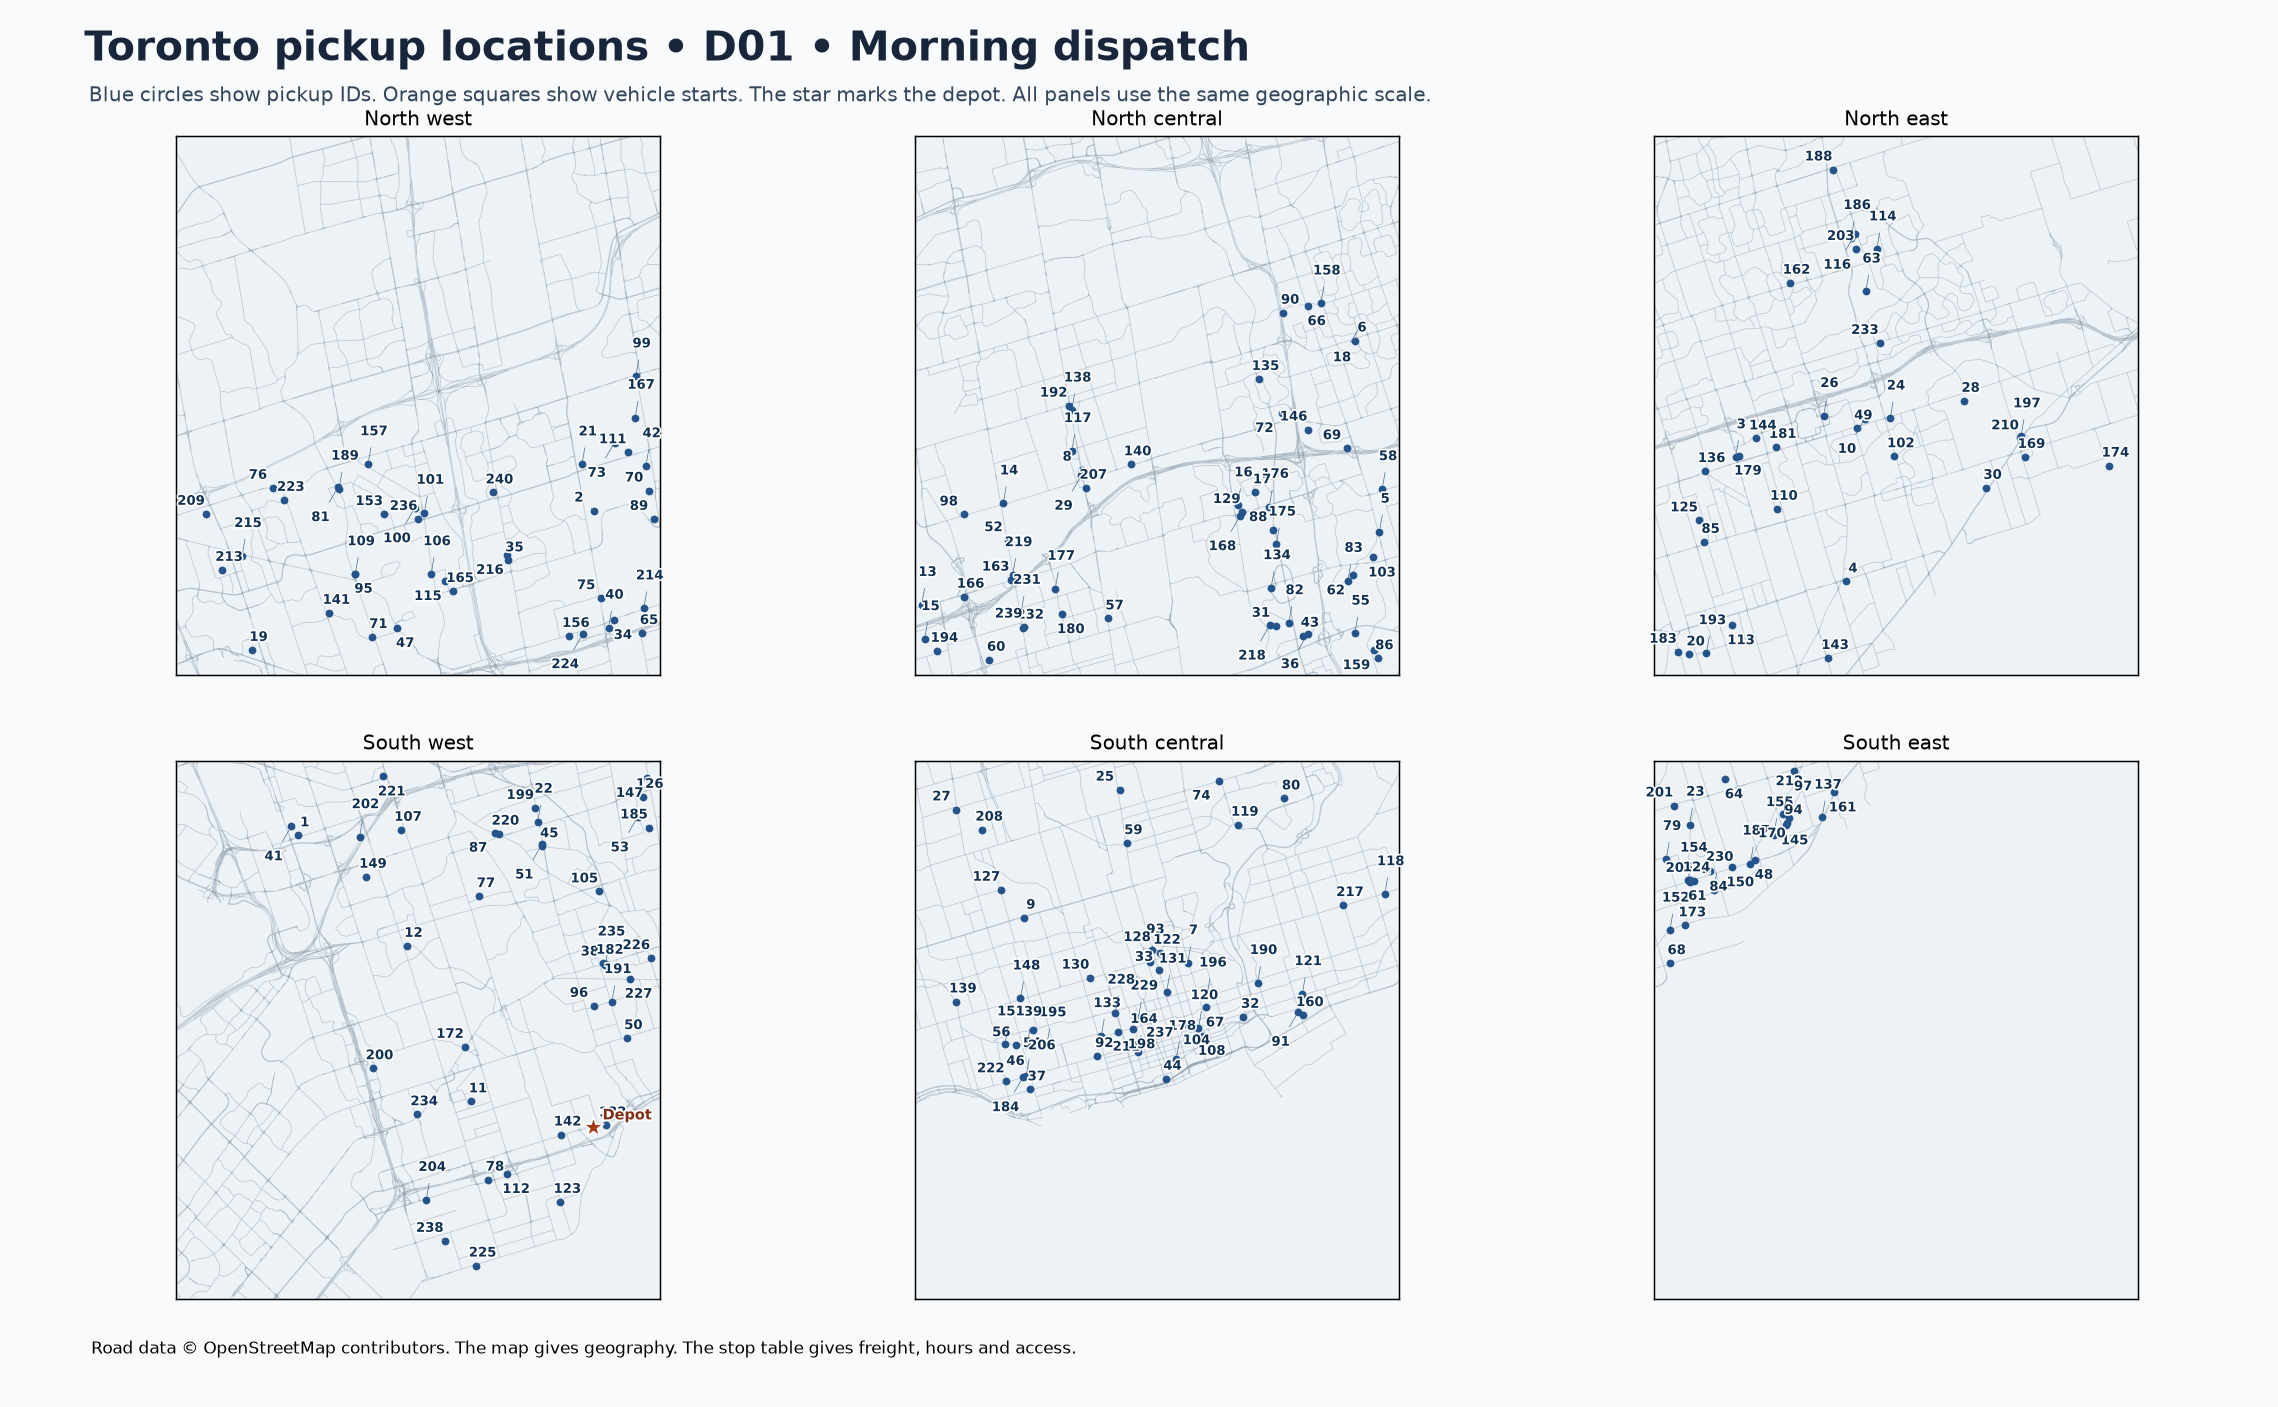

In [2]:
display(Image(filename='figures/input_map.png'))

The map shows the same day in six panels. The blue numbers are the pickup IDs and the depot is the orange star in the southwest. Grey lines show major roads. There are no route suggestions. Some numbers crowd together in the denser panels. The stop table still identifies every location and the road table gives directed drive times. A driver can use the image to see nearby sites, then use the tables to check whether it makes sense to put them on the same truck.

## 2. Planners and comparison

| Model | Version used | Provider and access | Size and precision | Output settings | Reason to include |
| --- | --- | --- | --- | --- | --- |
| GPT-6 Luna | gpt-6-luna | OpenAI through Codex CLI | Unpublished | Medium reasoning, one optional batched lookup | Owner-requested model with text and image input |
| GPT-6.1 Terra | gpt-6.1-terra | OpenAI through Codex CLI | Unpublished | Medium reasoning, one optional batched lookup | Owner-requested model with text and image input |
| GPT-6.2 Sol | gpt-6.2-sol | OpenAI through desktop Codex CLI | Unpublished | Medium reasoning, one optional batched lookup | Requested later as a newer model for the same routing cases |

These are the versioned model IDs selected in the Codex catalog. The CLI records which ID was requested and reports usage. This run's CLI records contain no dated backend revision or billed amount. Within each model, both image conditions use the same model settings and route response format.

OpenAI lists a May 18, 2026 knowledge cutoff for Luna and a June 1, 2026 cutoff for Terra and Sol. All pilot and held-out manifests and incidents were generated on November 18, 2026, after those dates. The public inputs locate the roads and addresses. The test targets are fresh assignments, loads and schedules generated for this experiment. [Luna model card](https://developers.openai.com/api/docs/models/gpt-6-luna) · [Terra model card](https://developers.openai.com/api/docs/models/gpt-6.1-terra) · [Sol model card](https://developers.openai.com/api/docs/models/gpt-6.2-sol)

Models get the same manifest, vehicle state, depot travel times and up to five nearby directed times per stop and eligible vehicle profile. They can ask for up to 72 more directed legs in one request. The lookup returns only times and distances. The map condition adds a street image with the same stop IDs, depot and vehicle origins.

```mermaid
flowchart TD
    P["Same manifest and fleet state<br/>Text or text plus map"] --> L["GPT-6 Luna, GPT-6.1 Terra or GPT-6.2 Sol<br/>Codex exec returns JSON"]
    L -->|"Optional lookup request"| T["Read-only leg table<br/>Up to 72 directed pairs"]
    T --> F["Same model via Codex exec<br/>JSON route list"]
    L -->|"Direct routes"| D["Independent checker<br/>Feasibility and cost"]
    F --> D
    D -->|"Validated routes"| W["OR-Tools starts from the model draft<br/>Uses remaining stage time"]
    D -->|"Unusable draft"| A["Unseeded OR-Tools fallback<br/>Uses remaining stage time"]
    W --> S["Independent replay of final plan"]
    A --> S
```

Each model and input condition runs in a separate session. The only second model turn is a reply to the optional travel request. If it is used, the planner waits for the requested time and distance rows. The method keeps the raw draft and scores it independently before using it for a solver start.

We score the direct draft and the solver-assisted plan. OR-Tools can start from a usable draft. For an unusable draft, we read the cold solver's best known plan at the time left after the model call. A timeout that consumes the whole budget leaves no time for a fallback.

Greedy insertion takes jobs in order of closing time and places each in the cheapest feasible position. It leaves a job unassigned if it finds no legal position. We compare OR-Tools from an empty start and from that simple order if it passes replay. OR-Tools searches for a complete plan and then tries to reduce cost. [OR-Tools routing tasks](https://developers.google.com/optimization/routing/routing_tasks)

Operating cost includes vehicle activation, mileage, and paid minutes driving, waiting and loading. All methods use the same simulated Canadian dollar rates.

### How the study got here

We tested two smaller schedules first, each with four vehicles and 24 pickups. Each model attempted four morning and four replan conditions at 75 seconds per session. The small schedules also let us inspect actual arrival calculations by hand.

| Model | Pilot sessions | Dispatchable mornings | Dispatchable replans | Unreadable | Timed out |
| --- | --- | --- | --- | --- | --- |
| Luna | 8 | 0 | 3 | 2 | 0 |
| Terra | 8 | 4 | 4 | 0 | 0 |
| Sol | 8 | 0 | 2 | 0 | 6 |

The pilot established that the pipeline could accept a draft and check it with or without an image. Two Luna map replies in the morning asked for too many road legs. For the held-out cases we kept the 72-leg allowance and returned the first 72 when a request was longer. We also made the paid time for active replan drivers start when they became ready, including wait time before moving. These changes are dated in the protocol. Pilot outcomes stay outside the held-out counts.

Sol joined after the first two models. The first CLI rejected its model ID at service startup. The installed desktop CLI supported it with the same account, so we reran the pilot through that version and used it for all Sol results below.

In [3]:
import datetime as dt
import hashlib
import json
import os
import re
import shutil
import signal
import subprocess
import tempfile
import time
from functools import lru_cache
from pathlib import Path
from threading import Lock

import requests


NOTEBOOK = "49-pickup-routing"
CODEX_VERSION = "0.160.1"
CODEX_SOL_VERSION = "0.169.0-alpha.11.1"
COLLECTION_MODELS = ("gpt-6-luna", "gpt-6.1-terra", "gpt-6.2-sol")
_CACHE_LOCKS = {}
DISABLED_CODEX_FEATURES = (
    "apps", "browser_use", "browser_use_external", "computer_use",
    "fast_mode", "goals", "hooks", "image_generation", "in_app_browser",
    "multi_agent", "plugins", "shell_snapshot", "shell_tool", "unified_exec",
    "view_image",
)
CODEX_EXEC_FLAGS = (
    "--ignore-user-config", "--ignore-rules", "--ephemeral",
    "--skip-git-repo-check", "--sandbox", "read-only", "--json", "--color", "never",
    "-c", 'approval_policy="never"', "-c", 'web_search="disabled"',
    "-c", "project_doc_max_bytes=0",
    *(part for name in DISABLED_CODEX_FEATURES for part in ("--disable", name)),
)


@lru_cache(maxsize=1)
def _trace_destination():
    host = os.environ.get("LANGFUSE_HOST", "http://localhost:3300").rstrip("/")
    auth = (os.environ.get("LANGFUSE_PUBLIC_KEY", ""), os.environ.get("LANGFUSE_SECRET_KEY", ""))
    if all(auth):
        try:
            if requests.get(f"{host}/api/public/health", timeout=2).ok:
                return host, auth
        except requests.RequestException:
            pass
    return None


def _trace_collection(destination, record):
    if destination is None:
        return

    def attribute(key, value):
        return {"key": key, "value": {"stringValue": value if isinstance(value, str) else json.dumps(value)}}

    request = record["request"]
    usage = record["usage"]
    input_cache = usage.get("cached_input_tokens", 0)
    reasoning = usage.get("reasoning_output_tokens", usage.get("reasoning_tokens", 0))
    usage_details = {}
    if usage:
        usage_details = {
            "input": max(0, usage.get("input_tokens", 0) - input_cache),
            "input_cache_read": input_cache,
            "output": max(0, usage.get("output_tokens", 0) - reasoning),
        }
        if usage.get("cache_write_input_tokens"):
            usage_details["input_cache_creation"] = usage["cache_write_input_tokens"]
        if reasoning:
            usage_details["output_reasoning"] = reasoning
    attrs = [
        attribute("langfuse.observation.type", "generation"),
        attribute("langfuse.observation.model.name", record["model"]),
        attribute("langfuse.observation.input", request),
        attribute("langfuse.observation.output", record["text"]),
        attribute("langfuse.trace.name", "49 pickup route planning"),
        {"key": "langfuse.trace.tags", "value": {"arrayValue": {"values": [{"stringValue": "nb49"}]}}},
        attribute("langfuse.environment", "notebook"),
        attribute("langfuse.trace.metadata.notebook", NOTEBOOK),
        attribute("langfuse.trace.metadata.cache_key", record["key"]),
    ]
    if usage_details:
        attrs.append(attribute("langfuse.observation.usage_details", usage_details))
    if record["session_id"]:
        attrs.append(attribute("langfuse.session.id", f"{NOTEBOOK}/{record['session_id']}"))
    if record["status"] != "ok":
        attrs.extend([
            attribute("langfuse.observation.level", "ERROR"),
            attribute("langfuse.observation.status_message", record["error"] or record["status"]),
        ])
    key = record["key"]
    start = dt.datetime.fromisoformat(record["started_at"]).timestamp()
    end = dt.datetime.fromisoformat(record["ended_at"]).timestamp()
    span = {
        "traceId": hashlib.sha256(f"{NOTEBOOK}|{key}".encode()).hexdigest()[:32],
        "spanId": hashlib.sha256(f"{NOTEBOOK}|{key}|gen|0".encode()).hexdigest()[:16],
        "name": "49 pickup route planning",
        "kind": 1,
        "attributes": attrs,
        "startTimeUnixNano": str(int(start * 1e9)),
        "endTimeUnixNano": str(int(end * 1e9)),
    }
    body = {"resourceSpans": [{
        "resource": {"attributes": [attribute("service.name", "experiment-notebooks")]},
        "scopeSpans": [{"scope": {"name": NOTEBOOK}, "spans": [span]}],
    }]}
    host, auth = destination
    try:
        requests.post(f"{host}/api/public/otel/v1/traces", auth=auth, json=body, timeout=10).raise_for_status()
    except requests.RequestException:
        pass


@lru_cache(maxsize=2)
def _codex_executable(required_version):
    if os.name == "nt":
        npm_codex = Path(os.getenv("APPDATA", "")) / "npm/node_modules/@openai/codex/node_modules/@openai"
        bundled = sorted(npm_codex.glob("codex-win32-*/vendor/*/bin/codex.exe"))
        candidates = bundled + [
            Path(os.getenv("LOCALAPPDATA", "")) / "Programs/OpenAI/Codex/bin/codex.exe",
            *(Path(directory) / "codex.exe" for directory in os.get_exec_path()),
        ]
    else:
        candidates = [Path(shutil.which("codex") or "codex")]
    versions = []
    for candidate in candidates:
        if candidate.is_file():
            version = subprocess.run(
                [str(candidate), "--version"], capture_output=True, text=True,
                check=True, timeout=5, creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0),
            ).stdout.strip()
            versions.append(version)
            if version == f"codex-cli {required_version}":
                return str(candidate.resolve())
    raise RuntimeError(f"Fresh calls require Codex CLI {required_version}. Found {versions or 'no native CLI'}.")


def _stop_process(process):
    if os.name == "nt":
        subprocess.run(
            ["taskkill", "/pid", str(process.pid), "/t", "/f"],
            capture_output=True, timeout=5, creationflags=subprocess.CREATE_NO_WINDOW,
        )
        if process.poll() is None:
            process.kill()
    else:
        try:
            os.killpg(process.pid, signal.SIGKILL)
        except ProcessLookupError:
            pass


def _safe_output(data):
    text = data.decode("utf-8", errors="replace")
    for name in ("OPENAI_API_KEY", "OPENROUTER_API_KEY", "ANTHROPIC_API_KEY", "GH_TOKEN",
                 "GITHUB_TOKEN", "LANGFUSE_PUBLIC_KEY", "LANGFUSE_SECRET_KEY"):
        secret = os.environ.get(name, "")
        if len(secret) >= 12:
            text = text.replace(secret, "[redacted]")
    return re.sub(r"\b(?:sk-(?:proj-)?|gh[pousr]_|github_pat_)[a-zA-Z0-9_-]{20,}", "[redacted]", text)


def _parse_codex_events(stdout):
    messages = []
    usage = {}
    model = None
    complete = False
    tool_types = set()
    errors = []
    for line in stdout.splitlines():
        try:
            event = json.loads(line)
        except json.JSONDecodeError:
            continue
        if not isinstance(event, dict):
            continue
        event_type = event.get("type")
        use_model = event.get("model")
        if isinstance(use_model, str):
            model = use_model
        if event_type in ("item.started", "item.completed"):
            item = event.get("item") or {}
            item_type = item.get("type")
            if item_type == "agent_message" and event_type == "item.completed":
                messages.append(item.get("text", ""))
            elif item_type in (
                "command_execution", "file_change", "mcp_tool_call", "web_search",
                "collab_agent_tool_call", "image_generation", "dynamic_tool_call",
            ):
                tool_types.add(item_type)
        elif event_type == "turn.completed":
            complete = True
            usage = event.get("usage") or {}
        elif event_type in ("error", "turn.failed"):
            error = event.get("error", {})
            errors.append(error.get("message") if isinstance(error, dict) and error.get("message") else event.get("message", "Codex error"))
    return (messages[-1] if messages else ""), usage, model, complete, sorted(tool_types), errors


def collect(prompt, model, image, cache_dir, timeout, fresh=False, *, effort="medium", session_id=None):
    """Execute one isolated model turn or replay its original reply and elapsed time."""
    if model not in COLLECTION_MODELS:
        raise ValueError(f"Unexpected model {model!r}")
    timeout = float(timeout)
    image_path = Path(image).resolve() if image is not None else None
    image_request = None
    if image_path is not None:
        image_request = {"file": image_path.name, "sha256": hashlib.sha256(image_path.read_bytes()).hexdigest()}
    request = {
        "model": model, "prompt": prompt, "image": image_request, "effort": effort,
        "timeout_seconds": timeout,
        "cli_version": CODEX_SOL_VERSION if model == "gpt-6.2-sol" else CODEX_VERSION,
        "cli_flags": list(CODEX_EXEC_FLAGS),
    }
    key = hashlib.sha256(json.dumps(request, ensure_ascii=False, sort_keys=True).encode()).hexdigest()
    cache_file = Path(cache_dir) / f"{key}.json"
    with _CACHE_LOCKS.setdefault(cache_file.resolve(), Lock()):
        if cache_file.is_file():
            return json.loads(cache_file.read_text(encoding="utf-8"))
        if not fresh:
            raise FileNotFoundError(f"Missing offline model cache {cache_file}")
        if timeout <= 0:
            raise ValueError("Timeout must be positive")
        return _collect_fresh(request, key, cache_file, image_path, session_id)


def _collect_fresh(request, key, cache_file, image_path, session_id):
    model = request["model"]
    effort = request["effort"]
    timeout = request["timeout_seconds"]
    executable = _codex_executable(request["cli_version"])
    cli_env = os.environ.copy()
    if model == "gpt-6.2-sol":
        cli_env.pop("OPENAI_API_KEY", None)
    destination = _trace_destination()
    args = [executable, "exec", *CODEX_EXEC_FLAGS, "-m", model, "-c", f"model_reasoning_effort={json.dumps(effort)}"]
    if image_path is not None:
        args.extend(["--image", str(image_path)])
    args.append("-")
    timed_out = False
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    created = dt.datetime.now(dt.timezone.utc)
    start = time.perf_counter()
    with tempfile.TemporaryDirectory(prefix="nb49-codex-") as isolated:
        with subprocess.Popen(
            args, cwd=isolated, env=cli_env, stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.PIPE,
            creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0), start_new_session=(os.name != "nt"),
        ) as process:
            try:
                stdout_bytes, stderr_bytes = process.communicate(request["prompt"].encode("utf-8"), timeout=timeout)
            except subprocess.TimeoutExpired:
                timed_out = True
                _stop_process(process)
                stdout_bytes, stderr_bytes = process.communicate()
            code = process.returncode
    elapsed = time.perf_counter() - start
    end = dt.datetime.now(dt.timezone.utc)
    stdout, stderr = _safe_output(stdout_bytes), _safe_output(stderr_bytes)
    reply, usage, reported_model, complete, tools_used, errors = _parse_codex_events(stdout)
    error = None
    if timed_out:
        status = "timeout"
        error = f"Exceeded {timeout:g} seconds"
    elif tools_used:
        status = "error"
        error = f"Attempted a tool call ({', '.join(tools_used)})"
    elif code != 0 or not complete:
        status = "error"
        error = errors[-1] if errors else f"Codex exited with code {code} without a completed turn"
    else:
        status = "ok"
    result = {
        "key": key, "model": reported_model or model, "reported_model": reported_model,
        "request": request, "response": reply, "text": reply, "usage": usage,
        "status": status, "error": error, "elapsed": elapsed, "duration_seconds": elapsed,
        "started_at": created.isoformat(), "ended_at": end.isoformat(), "session_id": session_id,
        "returncode": code, "stdout": stdout, "stderr": stderr, "tools_used": tools_used,
    }
    with tempfile.NamedTemporaryFile(
        dir=cache_file.parent, prefix=f".{key}.", suffix=".tmp", delete=False,
        encoding="utf-8", mode="w",
    ) as staging:
        json.dump(result, staging, ensure_ascii=False)
    try:
        try:
            os.link(staging.name, cache_file)
        except FileExistsError:
            return json.loads(cache_file.read_text(encoding="utf-8"))
    finally:
        Path(staging.name).unlink(missing_ok=True)
    _trace_collection(destination, result)
    return result

In [4]:
from collections import Counter
import re

import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.collections import LineCollection


MODELS = ("gpt-6-luna", "gpt-6.1-terra", "gpt-6.2-sol")
EFFORT = "medium"
CACHE = DATA / "cache"
STAGES = ("morning", "replan")
PILOT_DEADLINE = {"morning": 75, "replan": 75}
MAIN_DEADLINE = {"morning": 150, "replan": 120}
MAX_LOOKUP = 72
INPUT_RATE = 10
OUTPUT_RATE = 35


def map_image(case, stage, geography, street_lines, path):
    day = case[stage]
    labels, stops = case["labels"], day["stops"]
    groups = {}
    for vehicle in day["vehicles"]:
        groups.setdefault(vehicle["position"], []).append(vehicle["id"])
    lon_edges = np.linspace(min(g["lon"] for g in geography) - 0.008,
                            max(g["lon"] for g in geography) + 0.008, 4)
    lat_edges = np.linspace(min(g["lat"] for g in geography) - 0.006,
                            max(g["lat"] for g in geography) + 0.006, 3)
    fig, panels = plt.subplots(2, 3, figsize=(17, 10.5), constrained_layout=False)
    fig.subplots_adjust(left=0.032, right=0.984, top=0.903, bottom=0.077, wspace=0.07, hspace=0.16)
    fig.patch.set_facecolor("#f8fafc")
    fig.text(0.037, 0.957, f"Toronto pickup locations • {case['id']} • "
             f"{'Morning dispatch' if stage == 'morning' else '11:00 replan'}",
             fontsize=22, weight="bold", color="#17263a")
    fig.text(0.039, 0.928, "Blue circles show pickup IDs. Orange squares show vehicle starts. "
             "The star marks the depot. All panels use the same geographic scale.", fontsize=11, color="#33465c")
    stroke = [patheffects.withStroke(linewidth=1.8, foreground="white")]
    for row in range(2):
        iy = 1 - row
        for col in range(3):
            ax = panels[row, col]
            x0, x1 = lon_edges[col], lon_edges[col + 1]
            y0, y1 = lat_edges[iy], lat_edges[iy + 1]
            ax.add_collection(LineCollection(street_lines, color="#74889a", alpha=0.38, linewidth=0.43))
            ax.set_xlim(x0 - 0.002, x1 + 0.002)
            ax.set_ylim(y0 - 0.002, y1 + 0.002)
            ax.set_aspect(1 / math.cos(math.radians(43.7)))
            ax.set_title(f"{('North', 'South')[row]} {('west', 'central', 'east')[col]}", fontsize=11, pad=6)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_facecolor("#edf2f6")
            centers = []
            for stop in sorted(stops, key=lambda j: (geography[j]["lat"], geography[j]["lon"])):
                point = geography[stop]
                x, y = point["lon"], point["lat"]
                if x0 <= x < x1 and y0 <= y < y1:
                    centers.append((x, y, str(labels[stop])))
            if centers:
                ax.scatter([x for x, _, _ in centers], [y for _, y, _ in centers],
                           s=10, color="#23538b", zorder=3)
            width, height = x1 - x0, y1 - y0
            used = []
            for x, y, label in centers:
                def spacing(delta):
                    dx, dy = delta
                    nx, ny = (x - x0) / width + dx, (y - y0) / height + dy
                    edge = max(0, nx - 0.99, -nx, ny - 0.99, -ny)
                    separation = min(((nx - px) ** 2 + ((ny - py) * 0.8) ** 2
                                      for px, py in used), default=1)
                    return min(separation, 0.008) - dx * dx / 4 - dy * dy / 4 - edge
                candidates = [(0.014, 0.024), (-0.032, 0.024), (0.018, -0.030),
                              (-0.037, -0.030), (0.012, 0.062), (-0.038, -0.059)]
                dx, dy = max(candidates, key=spacing)
                used.append(((x - x0) / width + dx, (y - y0) / height + dy))
                ax.annotate(label, (x, y), (x + dx * width, y + dy * height),
                            fontsize=7.1, color="#103153", weight="bold", path_effects=stroke,
                            ha="center", va="center", zorder=4,
                            arrowprops={"arrowstyle": "-", "color": "#3c638a", "lw": 0.35, "shrinkA": 3})
            for point_id, vehicle_ids in groups.items():
                point = geography[point_id]
                x, y = point["lon"], point["lat"]
                if x0 <= x < x1 and y0 <= y < y1:
                    ax.scatter([x], [y], s=135 if point_id == 0 else 28, marker="*" if point_id == 0 else "s",
                               color="#a43b19", edgecolors="white", linewidths=0.9, zorder=5)
                    ax.annotate("Depot" if point_id == 0 else "/".join(vehicle_ids), (x, y),
                                xytext=(5, 4), textcoords="offset points", fontsize=7.8,
                                weight="bold", color="#7d2e13", path_effects=stroke, zorder=6)
    fig.text(0.04, 0.038, "Road data © OpenStreetMap contributors. "
             "The map gives geography. The stop table gives freight, hours and access.", fontsize=9)
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=134, facecolor=fig.get_facecolor())
    plt.close(fig)


def profile_name(profile):
    return ("van", "box")[profile]


def base_prompt(case, stage, geography, seconds, meters):
    task = case[stage]
    labels = case["labels"]
    stops = task["stops"]
    vehicles = task["vehicles"]
    candidates = sorted(stops, key=labels.get)
    fleet, manifest, road_notes = [], [], []
    for v in vehicles:
        fleet.append("|".join(map(str, [v["id"], v["kind"], profile_name(v["profile"]), labels[v["position"]],
                                  v["ready"], v["close"], *v["caps"], *v["load"],
                                  int(v["active"]), v["fixed"], v["km"], v["minute"]])))
    by_profile = {
        p: [j for j in candidates if any(v["profile"] == p and v["kind"] in stops[j]["allowed"]
                                       for v in vehicles)]
        for p in (0, 1)
    }
    for j in candidates:
        stop = stops[j]
        point = geography[j]
        manifest.append("|".join(map(str, [labels[j], point["address"], f"{point['lat']:.5f}",
                                      f"{point['lon']:.5f}", stop["lo"], stop["hi"], stop["service"],
                                      *stop["load"], "/".join(stop["allowed"]), stop["commodity"],
                                      int(stop.get("urgent", False))])))
        route_notes = []
        for p, possible in by_profile.items():
            if j not in possible:
                continue
            nearby = [k for k in possible if k != j and seconds[p, j, k] >= 0]
            close = sorted(nearby, key=lambda k: (seconds[p, j, k], labels[k]))[:5]
            helpful = ";".join(f"{labels[k]}/{leg_minutes(seconds, p, j, k)}" for k in close)
            outbound = leg_minutes(seconds, p, 0, j) if seconds[p, 0, j] >= 0 else "X"
            inbound = leg_minutes(seconds, p, j, 0) if seconds[p, j, 0] >= 0 else "X"
            route_notes.append(f"{profile_name(p)}:{outbound}/{inbound};{helpful}")
        road_notes.append(f"{labels[j]} " + " ".join(route_notes))
    replan = ""
    if stage == "replan":
        changes = [f"{labels[event['stop']]} {event['kind']}, deadline {event['old_hi']} -> {event['new_hi']}"
                   for event in task["events"]]
        committed = [f"{row['vehicle']} from {labels[row['from']]} to {labels[row['stop']]}, "
                     f"stop committed through minute {row['done']}" for row in task["locked"]]
        from_origins = []
        for v in vehicles:
            p, start = v["profile"], v["position"]
            eligible = [j for j in candidates if v["kind"] in stops[j]["allowed"] and seconds[p, start, j] >= 0]
            nearest = sorted(eligible, key=lambda j: (seconds[p, start, j], labels[j]))[:5]
            from_origins.append(f"{v['id']} " + ";".join(
                f"{labels[j]}/{leg_minutes(seconds, p, start, j)}" for j in nearest))
        replan = (
            "\nIt is now 11:00 (minute 660). Replan only the remaining manifest. "
            "The fleet table already reflects projected ready times and loads after committed work. "
            "Do not list completed or committed pickups again.\nDisruptions:\n"
            + "\n".join(changes) + "\nCommitted legs:\n" + "\n".join(committed)
            + "\nMinutes from projected vehicle origins to nearby eligible stops:\n"
            + "\n".join(from_origins) + "\n"
        )
    pay_policy = (
        "For a vehicle already active, charge time from its ready minute even if it waits before leaving. "
        "If a lookup asks for more than 72 directed legs, only the first 72 will be answered. "
        if case["id"].startswith("D") else ""
    )
    return (
        f"Dispatch case {case['id']}, {stage}. Produce an implementable plan for every listed pickup. "
        "Each stop ID must appear exactly once across all ordered vehicle routes. Output one JSON object only. "
        'Format {"routes":{"V01":[480,12,5],"V02":[490,4]}} where the first integer is departure minute '
        "since midnight (480 is 08:00), then only pending pickup IDs. Omit vehicles with no new pickups. "
        "The given current origin is implicit. Every used vehicle returns to depot 0. "
        "An already active unused vehicle returns to depot at its ready time. "
        "All operating times below are integer minutes since midnight. Vehicles can leave any time at or after ready. "
        "Drive, wait if early, then complete loading no later than the pickup deadline. "
        "Add load at every stop and stay under all three capacities. Use an allowed vehicle kind only. "
        "Return to depot by the shift deadline. Feasibility comes first. Then minimize cost in cents: "
        "new vehicle fixed costs plus distance at the vehicle's cents/km plus departure-to-return minutes "
        "at its cents/min. Existing active vehicles have no additional fixed cost. "
        + pay_policy
        + "Use the factual travel data below. Drives are directional and rounded up to minutes. "
        f'If necessary you may first ask for up to {MAX_LOOKUP} exact directed legs using only '
        '{"lookup":[["van",0,12],["box",5,4]]}. You get one lookup batch, after which you must return routes. '
        "Do not use code, shell, web, or other tools. The accompanying picture, when present, gives the same stop IDs. "
        "The output is scored by replay, so count every pickup and check equipment, loading, time and return.\n"
        + replan
        + "\nFleet\nvehicle|kind|road profile|origin ID|ready|depot due|kg cap|litre cap|pallet cap|"
          "kg aboard|litres aboard|pallets aboard|active|fixed cents|cents/km|cents/min\n"
        + "\n".join(fleet)
        + "\n\nPickups\nID|commercial address|latitude|longitude|open|finish by|load minutes|kg|litres|"
          "pallets|allowed kinds|load|urgent\n"
        + "\n".join(manifest)
        + "\n\nDirectional road minutes by pickup, depot to pickup/depot return, "
          "then up to five nearby pickup-ID/minutes pairs by profile:\n"
        + "\n".join(road_notes)
    )


def strict_json(text):
    value = text.strip()
    fence = chr(96) * 3
    if value.startswith(fence) and value.endswith(fence):
        value = re.sub(r"^\x60{3}(?:json)?\s*\n", "", value, count=1, flags=re.IGNORECASE)
        value = value[:-3].strip()

    def unique_object(pairs):
        value = {}
        for key, field in pairs:
            if key in value:
                raise ValueError(f"Repeated JSON object key {key}")
            value[key] = field
        return value

    return json.loads(value, object_pairs_hook=unique_object)


def parse_answer(text, labels, allow_oversize=False):
    try:
        answer = strict_json(text)
    except (ValueError, TypeError, AttributeError, RecursionError):
        return None
    if not isinstance(answer, dict):
        return None
    if set(answer) == {"lookup"} and isinstance(answer["lookup"], list):
        queries = answer["lookup"][:MAX_LOOKUP] if allow_oversize else answer["lookup"]
        if 0 < len(queries) <= MAX_LOOKUP and all(
            isinstance(q, list) and len(q) == 3 and q[0] in ("van", "box")
            and type(q[1]) is int and type(q[2]) is int for q in queries
        ):
            return "lookup", queries
    if set(answer) == {"routes"} and isinstance(answer["routes"], dict):
        routes = answer["routes"]
        if all(isinstance(route, list) and route and all(type(j) is int for j in route)
               for route in routes.values()):
            inverse = {label: j for j, label in labels.items()}
            return "routes", {
                v: [route[0], *(inverse.get(j, -1_000_000 - abs(j)) for j in route[1:])]
                for v, route in routes.items()
            }
    return None


def answer_legs(queries, labels, seconds, meters):
    inverse = {label: j for j, label in labels.items()}
    legs = []
    for profile, origin, target in queries:
        a, b = inverse.get(origin), inverse.get(target)
        p = ("van", "box").index(profile)
        if a is None or b is None or seconds[p, a, b] < 0:
            legs.append([profile, origin, target, None, None])
        else:
            legs.append([profile, origin, target, leg_minutes(seconds, p, a, b), int(meters[p, a, b])])
    return legs


def collect_plan(case, stage, model, use_map, geography, seconds, meters, deadline, fresh=False):
    task_id = f"{case['id']}/{stage}/{model}/{'map' if use_map else 'text'}"
    image = DATA / "maps" / f"{case['id']}_{stage}.png" if use_map else None
    prompt = base_prompt(case, stage, geography, seconds, meters)
    first = collect(prompt, model, image, CACHE, deadline, fresh=fresh, effort=EFFORT, session_id=task_id)
    calls = [first]
    parsed = parse_answer(first["text"], case["labels"], allow_oversize=not case["id"].startswith("P")) if first["status"] == "ok" else None
    if parsed and parsed[0] == "lookup":
        residual = round(deadline - first["elapsed"], 3)
        if residual > 1:
            legs = answer_legs(parsed[1], case["labels"], seconds, meters)
            second_prompt = (
                prompt + "\nYou asked for road times. These rows give road profile, origin, target, "
                "driving minutes, metres. Null means the leg is unavailable. "
                "Now return the routes in the required JSON format.\n" + json.dumps(legs, separators=(",", ":"))
            )
            second = collect(second_prompt, model, image, CACHE, residual, fresh=fresh,
                             effort=EFFORT, session_id=task_id)
            calls.append(second)
            parsed = parse_answer(second["text"], case["labels"]) if second["status"] == "ok" else None
        else:
            return {"plan": None, "status": "timeout", "elapsed": first["elapsed"], "calls": calls}
    status = calls[-1]["status"]
    if status == "ok":
        status = "readable" if parsed and parsed[0] == "routes" else "unreadable"
    elapsed = sum(c["elapsed"] for c in calls)
    if elapsed > deadline:
        status = "timeout"
    return {"plan": parsed[1] if status == "readable" else None, "status": status, "elapsed": elapsed, "calls": calls}


def model_units(calls):
    input_tokens = sum((c["usage"] or {}).get("input_tokens", 0) or 0 for c in calls)
    output_tokens = sum((c["usage"] or {}).get("output_tokens", 0) or 0 for c in calls)
    return {
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "estimated_usd": (input_tokens * INPUT_RATE + output_tokens * OUTPUT_RATE) / 1_000_000,
    }

In [5]:
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from time import perf_counter


def load_world():
    geography = json.loads((DATA / "geography.json").read_text(encoding="utf-8"))
    with np.load(DATA / "road_matrix.npz", allow_pickle=False) as matrix:
        seconds, meters = matrix["seconds"], matrix["meters"]
    assert len(geography) == 241 and seconds.shape == meters.shape == (2, 241, 241)
    assert (seconds >= 0).all() and (meters >= 0).all()
    assert all(not np.diag(seconds[i]).any() for i in range(2))
    return geography, seconds, meters


def run_spec(cases, deadlines, models=None):
    models = MODELS if models is None else models
    return [(case, stage, model, mapped, deadlines[stage])
            for case in cases for stage in STAGES for model in models for mapped in (False, True)]


def method_label(model, mapped):
    name = {"gpt-6-luna": "Luna", "gpt-6.1-terra": "Terra", "gpt-6.2-sol": "Sol"}[model]
    return f"{name} {'map' if mapped else 'text'}"


def session_summary(result):
    return {
        **{key: result[key] for key in ("plan", "status", "elapsed")},
        "keys": [call["key"] for call in result["calls"]],
        "errors": [call["error"] for call in result["calls"] if call["error"]],
        "usage_missing": sum(not call["usage"] for call in result["calls"]),
        **model_units(result["calls"]),
    }


def gather_sessions(cases, deadlines, geography, seconds, meters, *, fresh=False, workers=8, models=None):
    jobs = run_spec(cases, deadlines, models)
    results = {}
    if not fresh:
        for case, stage, model, mapped, budget in jobs:
            key = (case["id"], stage, method_label(model, mapped))
            result = collect_plan(case, stage, model, mapped, geography, seconds, meters, budget)
            results[key] = session_summary(result)
        return results
    random.Random(7490).shuffle(jobs)
    with ThreadPoolExecutor(max_workers=workers) as executor:
        pending = {
            executor.submit(collect_plan, case, stage, model, mapped, geography, seconds, meters,
                            budget, fresh=True):
            (case["id"], stage, method_label(model, mapped))
            for case, stage, model, mapped, budget in jobs
        }
        for index, finished in enumerate(as_completed(pending), start=1):
            key = pending[finished]
            record = session_summary(finished.result())
            results[key] = record
            print(index, "/", len(jobs), *key, record["status"], f"{record['elapsed']:.1f}s",
                  f"USD {record['estimated_usd']:.3f}", flush=True)
    return results


def operating_result(case, stage, label, row, seconds, meters):
    day = case[stage]
    plan = row["plan"]
    score = None if plan is None else evaluate(day["stops"], day["vehicles"], seconds, meters, plan)
    changed = None
    extra = None
    if stage == "replan" and score is not None:
        changed = sum(plan.get(v["id"], [])[1:] != day["unchanged"][v["id"]][1:]
                      for v in day["vehicles"])
        if score["feasible"]:
            extra = score["minutes"] - day["unchanged_minutes"]
    score = score or {}
    return {
        "case": case["id"], "stratum": case["stratum"], "stage": stage, "method": label,
        "required": len(day["stops"]), "status": row["status"],
        "feasible": bool(score.get("feasible")), "served": score.get("served", 0),
        "urgent_served": score.get("urgent_served", 0), "missing": score.get("missing"),
        "duplicate": score.get("duplicate"), "violations": score.get("violations", {}),
        "cost": score.get("cost"), "km": score.get("km"), "minutes": score.get("minutes"),
        "vehicles_used": score.get("vehicles_used"), "elapsed": row["elapsed"],
        "first_feasible": row.get("first_feasible"),
        "drivers_changed": changed, "extra_minutes": extra, "seed_used": row.get("seed_used"),
        "solver_fallback": row.get("solver_fallback"),
    }


def cold_incumbent(cold, cutoff):
    if cutoff <= 0:
        return None
    return next((row["plan"] for row in reversed(cold["best_history"]) if row["elapsed"] <= cutoff), None)


def measure_baselines(case, stage, budget, road_profile):
    seconds, meters = road_profile
    day = case[stage]
    stops, vehicles = day["stops"], day["vehicles"]
    started = perf_counter()
    insertion = greedy(stops, vehicles, seconds, meters)
    spent = perf_counter() - started
    feasible = evaluate(stops, vehicles, seconds, meters, insertion)["feasible"]
    cold = optimize(stops, vehicles, seconds, meters, budget, checkpoints=[budget])
    methods = {
        "Insertion": {"plan": insertion, "status": "readable", "elapsed": spent},
        "OR-Tools": {k: cold[k] for k in ("plan", "status", "elapsed", "first_feasible", "seed_used")},
    }
    left = max(0.0, budget - spent)
    if feasible:
        seeded = optimize(stops, vehicles, seconds, meters, left, seed=insertion)
        methods["Insertion + solver"] = {
            **{k: seeded[k] for k in ("plan", "status", "first_feasible", "seed_used")},
            "elapsed": spent + seeded["elapsed"], "solver_fallback": bool(seeded["seed_rejected"]),
        }
    else:
        offered = cold_incumbent(cold, left)
        methods["Insertion + solver"] = {
            "plan": offered, "status": "fallback" if offered is not None else "no_plan",
            "elapsed": budget, "solver_fallback": True, "seed_used": False,
        }
    return {"plans": methods, "cold": cold}


def compare_optimizers(case, stage, drafts, budget, road_profile, baselines=None):
    seconds, meters = road_profile
    day = case[stage]
    stops, vehicles = day["stops"], day["vehicles"]
    if baselines is None:
        baselines = measure_baselines(case, stage, budget, road_profile)
    methods, cold = dict(baselines["plans"]), baselines["cold"]
    for key, draft in drafts.items():
        remaining = max(0.0, budget - draft["elapsed"])
        valid_draft = draft["plan"] is not None and evaluate(stops, vehicles, seconds, meters, draft["plan"])["feasible"]
        seeded = optimize(stops, vehicles, seconds, meters, remaining, seed=draft["plan"]) if (
            valid_draft and remaining > 0
        ) else None
        if seeded and seeded["seed_used"]:
            candidate = seeded["plan"]
            status = seeded["status"]
        else:
            candidate = cold_incumbent(cold, remaining)
            if valid_draft:
                if candidate is None or evaluate(stops, vehicles, seconds, meters, candidate)["cost"] > evaluate(
                    stops, vehicles, seconds, meters, draft["plan"]
                )["cost"]:
                    candidate = draft["plan"]
            status = "fallback" if remaining > 0 and candidate is not None else "no_plan"
        methods[key + " + solver"] = {
            "plan": candidate, "status": status,
            "elapsed": draft["elapsed"] + seeded["elapsed"] if seeded else (
                budget if remaining > 0 else draft["elapsed"]),
            "solver_fallback": remaining > 0 and (seeded is None or not seeded["seed_used"]),
            "seed_used": bool(seeded and seeded["seed_used"]),
        }
    history = [{k: row[k] for k in ("cost", "elapsed")} for row in cold["best_history"]]
    return methods, history


def score_all(cases, sessions, solver_records, seconds, meters):
    rows = []
    for case in cases:
        for stage in STAGES:
            run = solver_records[f"{case['id']}/{stage}"]
            drafts = {key[2]: row for key, row in sessions.items() if key[:2] == (case["id"], stage)}
            for method, record in {**run["plans"], **drafts}.items():
                rows.append(operating_result(case, stage, method, record, seconds, meters))
    return rows


def repair_existing_list(case, seconds, meters):
    """Change only an incident vehicle's ordering, using the old list as input."""
    day = case["replan"]
    start = perf_counter()
    revised = deepcopy(day["unchanged"])
    for event in day["events"]:
        stop_id = event["stop"]
        v = next(v for v in day["vehicles"] if stop_id in revised[v["id"]][1:])
        depart, *visits = revised[v["id"]]
        previous = visits.index(stop_id)
        others = [j for j in visits if j != stop_id]
        manifest = {j: day["stops"][j] for j in visits}
        options = []
        for before in range(previous):
            new = [depart, *others[:before], stop_id, *others[before:]]
            replay = evaluate(manifest, [v], seconds, meters, {v["id"]: new})
            if replay["feasible"]:
                options.append((replay["cost"], before, new))
        if not options:
            return {"plan": None, "elapsed": perf_counter() - start, "status": "no_plan"}
        revised[v["id"]] = min(options)[2]
    return {"plan": revised, "elapsed": perf_counter() - start, "status": "readable"}


def sensitivity_case(case, seconds, meters):
    result = {}
    for stage in STAGES:
        task = case[stage]
        other = optimize(task["stops"], task["vehicles"], seconds, meters, 2.0,
                         strategy="LOCAL_CHEAPEST_INSERTION")
        result[stage] = {"Alternate OR-Tools start": other}
        if stage == "replan":
            result[stage]["Repair previous list"] = repair_existing_list(case, seconds, meters)
    return result

## 3. Checking a plan

The checker replays each vehicle's departure and stop order. It reads directed travel times, waits for opening, loads, checks the deadline and adds freight to the onboard weight, volume and pallet totals. It then checks the return trip against the shift end.

Timeouts, malformed replies and responses without routes provide no plan to score. In a readable plan, timing, equipment and capacity failures are counted separately. A stop can have more than one violation. Any violation makes the complete day's plan fail.

The partial pickup score helps explain invalid plans. For example, if a day needs 240 pickups and an answer serves 200 within their local windows, equipment and load rules, its partial coverage is 200/240, or 83.3%. That day contributes zero to the dispatchable-day count if any required pickup is missing or any route breaks a rule. The partial score credits distinct stops that pass their individual checks even if another copy appears in the plan or the truck eventually returns late. We pair operating cost only across days where both compared methods produce a clean plan, and we say how many days are in each comparison.

### A complete route from raw answer to score on pilot P01

Terra received the pickup table and its map. The first sentence of the prompt asks for an implementable plan for every listed pickup. The required JSON object uses the vehicle ID as a key and starts the value with a departure minute, followed by the pickup IDs in order. The same request text goes to Luna and Sol. The map conditions also receive the frozen image. The direct evaluator infers the start location and depot return from the manifest.

The opening instructions below are copied from the cached request. The full stop and road tables are in the linked record.

```text
Dispatch case P01, morning. Produce an implementable plan for every listed pickup. Each stop ID must appear exactly once across all ordered vehicle routes. Output one JSON object only. Format {"routes":{"V01":[480,12,5],"V02":[490,4]}} where the first integer is departure minute since midnight (480 is 08:00), then only pending pickup IDs. Omit vehicles with no new pickups.
```

The model returned the following route object.

```json
{"routes":{"V01":[510,13,21,7,3,6,22],"V02":[540,2,10,1,12,11,16,14],"V03":[530,23,17,24,15,8,19],"V04":[534,9,20,18,5,4]}}
```

Read the row for **V03**, the refrigerated van. Its sequence is 23 → 17 → 24 → 15 → 8 → 19. The evaluator checks that every one of these jobs allows a chilled vehicle, then works through the pickup clock and adds each new load to what is already inside the van.

| Pickup | Address | Window | Service min | Arrives | Starts | Ends | Load aboard |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 23 | 1928 Queen St E | 08:00–09:43 | 11 | 09:16 | 09:16 | 09:27 | 141 kg / 833 L |
| 17 | 1416 Victoria Park Ave | 08:19–10:14 | 11 | 09:42 | 09:42 | 09:53 | 236 kg / 1,501 L |
| 24 | 3601 Victoria Park Ave | 09:17–10:52 | 12 | 10:12 | 10:12 | 10:24 | 307 kg / 3,019 L |
| 15 | 3030 Don Mills Rd E | 12:27–13:16 | 9 | 10:33 | 12:27 | 12:36 | 403 kg / 3,525 L |
| 8 | 801 York Mills Rd | 12:27–14:17 | 13 | 12:49 | 12:49 | 13:02 | 492 kg / 4,533 L |
| 19 | 1 Valleybrook Dr | 12:27–14:30 | 9 | 13:07 | 13:07 | 13:16 | 633 kg / 5,473 L |

Take the first leg. The van leaves at 08:50. The drive to pickup 23 takes 26 scheduled minutes and it arrives at 09:16. Loading starts at 09:16 and takes 11 minutes, so the finish at 09:27 is checked against the 09:43 deadline. The remaining rows repeat that arithmetic with the van's new location and load. The van returns at 13:44, before its 16:30 shift deadline. The checker independently accepted all 24 pickups across the 4 vehicles on this pilot day. This small case demonstrates the output format and a genuine success. The held-out mornings have ten times as many pickups.

[Full request and reply, turn 1](data/cache/27edf8d63791063c8c5545c56edcaac908fea9c0204999dd554228e099b6bf76.json) · [Full request and reply, turn 2](data/cache/06ed09599439394dab79d4113949aa974e5c3f543c4cb148dd698bc9894b3aa5.json)

In [6]:
"""Dispatch replay, deterministic insertion, and the OR-Tools comparison."""

from collections import Counter
from numbers import Integral
from time import perf_counter

import numpy as np
from ortools.constraint_solver import pywrapcp, routing_enums_pb2


_CAPACITY_FIELDS = ("over_kg", "over_litres", "over_pallets")


def _route_distance_cost(meters, cents_per_km):
    return (meters * cents_per_km + 500) // 1000


def _integer(value):
    return isinstance(value, Integral) and not isinstance(value, bool)


def _road_leg(seconds, meters, profile, origin, destination):
    duration = int(seconds[profile, origin, destination])
    distance = int(meters[profile, origin, destination])
    if duration < 0 or distance < 0:
        return None, None
    return (duration + 59) // 60, distance


def _replay(stops, vehicle, seconds, meters, departure, visits, details):
    """Replay a fixed departure and visit order, waiting until loading is allowed."""
    now = departure
    position = vehicle["position"]
    load = list(vehicle["load"])
    profile = vehicle["profile"]
    distance = 0
    vehicle_id = vehicle["id"]
    operating = bool(visits) or vehicle["active"]
    issues = Counter()
    timeline = []
    served = set()
    if not operating:
        return issues, 0, 0, 0, served, None

    departure_valid = (vehicle["ready"] <= departure <= vehicle["close"]
                       and departure == vehicle.get("fixed_departure", departure))
    if not departure_valid:
        issues["invalid_departure"] += 1
    initial_capacity_issues = tuple(
        field for field, amount, cap in zip(_CAPACITY_FIELDS, load, vehicle["caps"])
        if amount > cap
    )
    issues.update(initial_capacity_issues)
    distance_cost = 0
    for stop_id in visits:
        stop = stops[stop_id]
        duration, leg_meters = _road_leg(seconds, meters, profile, position, stop_id)
        stop_issues = []
        if duration is None:
            stop_issues.append("unreachable_leg")
        if vehicle["kind"] not in stop["allowed"]:
            stop_issues.append("incompatible")
        arrival = None if now is None or duration is None else now + duration
        start = None if arrival is None else max(arrival, stop["lo"])
        end = None if start is None else start + stop["service"]
        if end is not None and end > stop["hi"]:
            stop_issues.append("late_window")
        for index, amount in enumerate(stop["load"]):
            load[index] += amount
            if load[index] > vehicle["caps"][index]:
                stop_issues.append(_CAPACITY_FIELDS[index])
        if leg_meters is not None:
            distance += leg_meters
            distance_cost += _route_distance_cost(leg_meters, vehicle["km"])
        if end is not None and departure_valid and not stop_issues:
            served.add(stop_id)
        issues.update(stop_issues)
        if details:
            timeline.append({
                "stop": stop_id, "arrival": arrival, "start": start, "end": end,
                "load": load.copy(), "violations": stop_issues,
            })
        position, now = stop_id, end

    duration, leg_meters = _road_leg(seconds, meters, profile, position, vehicle.get("end_position", 0))
    if duration is None:
        issues["unreachable_leg"] += 1
    else:
        distance += leg_meters
        distance_cost += _route_distance_cost(leg_meters, vehicle["km"])
    returned = None if now is None or duration is None else now + duration
    if returned is not None and returned > vehicle["close"]:
        issues["late_return"] += 1
    paid_from = vehicle["ready"] if vehicle["active"] else departure
    minutes = None if returned is None else returned - paid_from
    fixed = 0 if vehicle["active"] else vehicle["fixed"]
    cost = None if minutes is None else fixed + distance_cost + minutes * vehicle["minute"]
    route = None
    if details:
        route = {
            "id": vehicle_id, "departure": departure, "return": returned, "minutes": minutes,
            "start_position": vehicle["position"], "initial_load": list(vehicle["load"]),
            "km": distance / 1000, "cost": cost, "stops": timeline, "violations": dict(issues),
        }
    return issues, cost, distance, minutes, served, route


def evaluate(stops, vehicles, seconds, meters, plan, details=False):
    """Check coverage, replay routes independently, and total pickup and cost outcomes."""
    counts = Counter()
    violations = Counter()
    if not isinstance(plan, dict):
        violations["invalid_plan"] += 1
        plan = {}
    vehicle_ids = {vehicle["id"] for vehicle in vehicles}
    violations["unknown_vehicle"] += len(set(plan) - vehicle_ids)

    total_meters, total_money, total_minutes, in_use = 0, 0, 0, 0
    served = set()
    routes = {}
    for vehicle in vehicles:
        vehicle_id = vehicle["id"]
        route = plan.get(vehicle_id, [vehicle["ready"]])
        if not isinstance(route, (tuple, list)) or not route or not _integer(route[0]):
            violations["invalid_route"] += 1
            route = [vehicle["ready"]]
        visits = []
        for stop_id in route[1:]:
            if not _integer(stop_id) or stop_id not in stops:
                violations["unknown_stop"] += 1
                continue
            visits.append(int(stop_id))
        counts.update(visits)
        in_use += bool(visits) or vehicle["active"]
        issues, cost, distance, minutes, served_here, timeline = _replay(
            stops, vehicle, seconds, meters, int(route[0]), visits, details,
        )
        violations.update(issues)
        total_meters += distance
        total_money = None if total_money is None or cost is None else total_money + cost
        total_minutes = None if total_minutes is None or minutes is None else total_minutes + minutes
        served.update(served_here)
        if timeline is not None:
            routes[vehicle_id] = timeline

    missing_ids = sorted(set(stops) - set(counts))
    duplicate_ids = sorted(stop_id for stop_id, count in counts.items() if count > 1)
    issues = dict(+violations)
    urgent = {stop_id for stop_id, stop in stops.items() if stop.get("urgent")}
    result = {
        "feasible": not (issues or missing_ids or duplicate_ids),
        "missing": len(missing_ids), "missing_ids": missing_ids,
        "duplicate": sum(counts[stop_id] - 1 for stop_id in duplicate_ids),
        "duplicate_ids": duplicate_ids, "violations": issues,
        "cost": total_money, "km": total_meters / 1000, "minutes": total_minutes,
        "vehicles_used": in_use, "served": len(served),
        "urgent_total": len(urgent), "urgent_served": len(served & urgent),
    }
    if details:
        result["routes"] = routes
        result["served_ids"] = sorted(served)
    return result


def _fixed_order_cost(stops, vehicle, road_minutes, road_meters, visits):
    """Find the latest feasible departure and its cost for a fixed stop sequence."""
    position = vehicle["position"]
    latest_departure = vehicle["close"]
    earliest_without_wait = vehicle["ready"]
    elapsed, distance_cost = 0, 0
    for stop_id in visits:
        stop = stops[stop_id]
        leg = int(road_minutes[position, stop_id])
        if leg < 0:
            return None
        distance_cost += _route_distance_cost(int(road_meters[position, stop_id]), vehicle["km"])
        elapsed += leg
        earliest_without_wait = max(earliest_without_wait, stop["lo"] - elapsed)
        elapsed += stop["service"]
        latest_departure = min(latest_departure, stop["hi"] - elapsed)
        if earliest_without_wait > stop["hi"] - elapsed or latest_departure < vehicle["ready"]:
            return None
        position = stop_id

    leg = int(road_minutes[position, 0])
    if leg < 0:
        return None
    elapsed += leg
    if earliest_without_wait > vehicle["close"] - elapsed:
        return None
    latest_departure = min(latest_departure, vehicle["close"] - elapsed)
    departure = vehicle["ready"] if vehicle["active"] else latest_departure
    minutes = elapsed + max(earliest_without_wait - departure, 0)
    distance_cost += _route_distance_cost(int(road_meters[position, 0]), vehicle["km"])
    fixed = vehicle["fixed"] if visits and not vehicle["active"] else 0
    return fixed + distance_cost + minutes * vehicle["minute"], departure


def greedy(stops, vehicles, seconds, meters):
    """Try stops by closing time and insert at the cheapest feasible position."""
    route_minutes = np.where((seconds < 0) | (meters < 0), -1, (seconds + 59) // 60)
    route_orders = {vehicle["id"]: [] for vehicle in vehicles}
    depart = {vehicle["id"]: vehicle["ready"] for vehicle in vehicles}
    load = {vehicle["id"]: list(vehicle["load"]) for vehicle in vehicles}
    route_cost = {}
    for vehicle in vehicles:
        options = _fixed_order_cost(
            stops, vehicle, route_minutes[vehicle["profile"]], meters[vehicle["profile"]], [],
        )
        route_cost[vehicle["id"]] = options[0] if vehicle["active"] and options is not None else 0

    for stop_id in sorted(stops, key=lambda index: (stops[index]["hi"], stops[index]["lo"], index)):
        stop = stops[stop_id]
        best = None
        for vehicle in vehicles:
            vehicle_id = vehicle["id"]
            if vehicle["kind"] not in stop["allowed"] or any(
                used + extra > cap for used, extra, cap in zip(
                    load[vehicle_id], stop["load"], vehicle["caps"]
                )
            ):
                continue
            order = route_orders[vehicle_id]
            profile = vehicle["profile"]
            for index in range(len(order) + 1):
                revised = order[:index] + [stop_id] + order[index:]
                options = _fixed_order_cost(stops, vehicle, route_minutes[profile], meters[profile], revised)
                if options is None:
                    continue
                cost, departure = options
                key = (cost - route_cost[vehicle_id], vehicle_id, index)
                if best is None or key < best[0]:
                    best = (key, vehicle_id, revised, cost, departure)
        if best is not None:
            _, vehicle_id, revised, cost, departure = best
            route_orders[vehicle_id] = revised
            route_cost[vehicle_id] = cost
            depart[vehicle_id] = departure
            load[vehicle_id] = [a + b for a, b in zip(load[vehicle_id], stop["load"])]
    return {
        vehicle_id: [depart[vehicle_id], *order]
        for vehicle_id, order in route_orders.items() if order
    }


def _build_routing(stops, vehicles, seconds, meters):
    """Encode the same hard rules in time and capacity dimensions."""
    stop_ids = sorted(stops)
    node_of_stop = {stop_id: index + 1 for index, stop_id in enumerate(stop_ids)}
    count = len(vehicles)
    first_start = len(stop_ids) + 1
    locations = np.array([0, *stop_ids, *(vehicle["position"] for vehicle in vehicles)])
    manager = pywrapcp.RoutingIndexManager(
        len(locations), count, list(range(first_start, first_start + count)), [0] * count,
    )
    routing = pywrapcp.RoutingModel(manager)
    horizon = max(vehicle["close"] for vehicle in vehicles)
    service = np.array([0, *(stops[stop_id]["service"] for stop_id in stop_ids), *([0] * count)])

    time_callbacks, distance_callbacks = {}, {}
    for vehicle_index, vehicle in enumerate(vehicles):
        profile = vehicle["profile"]
        if profile not in time_callbacks:
            leg_seconds = seconds[profile][locations[:, None], locations].astype(np.int64)
            leg_meters = meters[profile][locations[:, None], locations].astype(np.int64)
            times = np.where(
                (leg_seconds < 0) | (leg_meters < 0), horizon + 1,
                (leg_seconds + 59) // 60 + service[:, None],
            )
            time_callbacks[profile] = routing.RegisterTransitMatrix(times.tolist())
        price_key = (profile, vehicle["km"])
        if price_key not in distance_callbacks:
            distances = meters[profile][locations[:, None], locations].astype(np.int64)
            costs = np.maximum(0, _route_distance_cost(distances, vehicle["km"]))
            distance_callbacks[price_key] = routing.RegisterTransitMatrix(costs.tolist())
        routing.SetArcCostEvaluatorOfVehicle(distance_callbacks[price_key], vehicle_index)
        routing.SetFixedCostOfVehicle(0 if vehicle["active"] else vehicle["fixed"], vehicle_index)
        routing.SetVehicleUsedWhenEmpty(bool(vehicle["active"]), vehicle_index)

    routing.AddDimensionWithVehicleTransits(
        [time_callbacks[vehicle["profile"]] for vehicle in vehicles], horizon, horizon, False, "Clock",
    )
    clock = routing.GetDimensionOrDie("Clock")
    for stop_id in stop_ids:
        stop = stops[stop_id]
        index = manager.NodeToIndex(node_of_stop[stop_id])
        allowed = [i for i, vehicle in enumerate(vehicles) if vehicle["kind"] in stop["allowed"]]
        if not allowed or stop["lo"] > stop["hi"] - stop["service"]:
            return None
        # VehicleVar binding is stable across wheels whose vector<int> adapter for
        # SetAllowedVehiclesForIndex expects a different SWIG buffer type.
        clock.CumulVar(index).SetRange(stop["lo"], stop["hi"] - stop["service"])
        routing.VehicleVar(index).SetValues(allowed)
    for index, vehicle in enumerate(vehicles):
        departure = clock.CumulVar(routing.Start(index))
        departure.SetRange(vehicle["ready"], vehicle["close"])
        routing.solver().Add(departure <= vehicle["ready"] + horizon * routing.ActiveVehicleVar(index))
        clock.CumulVar(routing.End(index)).SetRange(vehicle["ready"], vehicle["close"])
        if vehicle["active"]:
            clock.SetCumulVarSoftUpperBound(routing.End(index), vehicle["ready"], vehicle["minute"])
        else:
            clock.SetSpanCostCoefficientForVehicle(vehicle["minute"], index)
        routing.AddVariableMaximizedByFinalizer(departure)
        routing.AddVariableMinimizedByFinalizer(clock.CumulVar(routing.End(index)))

    for unit, name in enumerate(("Weight", "Volume", "Pallets")):
        demand = [0, *(stops[stop_id]["load"][unit] for stop_id in stop_ids), *([0] * count)]
        callback = routing.RegisterUnaryTransitVector(demand)
        caps = [vehicle["caps"][unit] for vehicle in vehicles]
        routing.AddDimensionWithVehicleCapacity(callback, 0, caps, False, name)
        dimension = routing.GetDimensionOrDie(name)
        for index, vehicle in enumerate(vehicles):
            dimension.CumulVar(routing.Start(index)).SetValue(vehicle["load"][unit])
    return manager, routing, clock, locations, node_of_stop


def optimize(stops, vehicles, seconds, meters, timeout, seed=None, checkpoints=None,
             strategy="PARALLEL_CHEAPEST_INSERTION"):
    """Run OR-Tools with a wall-clock budget including model setup."""
    start = perf_counter()
    cutoffs = sorted((float(value), str(value)) for value in (checkpoints or []))
    saved = {}
    best = None
    best_cost = None
    first_feasible = None
    history = []
    used = False
    seed_score = None if seed is None else evaluate(stops, vehicles, seconds, meters, seed)
    rejected = seed_score is not None and not seed_score["feasible"]

    def finish(plan, status):
        for _, label in cutoffs:
            saved.setdefault(label, best)
        return {
            "plan": plan, "status": status, "elapsed": perf_counter() - start,
            "seed_used": used, "seed_rejected": rejected, "first_feasible": first_feasible,
            "checkpoints": saved, "best_history": history,
        }

    if timeout <= perf_counter() - start:
        return finish(None, "deadline")
    if not vehicles:
        return finish(None if stops else {}, "no_vehicles")
    if any(
        vehicle["ready"] > vehicle["close"] or any(
            amount > cap for amount, cap in zip(vehicle["load"], vehicle["caps"])
        )
        for vehicle in vehicles
    ):
        return finish(None, "invalid_fleet_state")

    problem = _build_routing(stops, vehicles, seconds, meters)
    if problem is None:
        return finish(None, "impossible_stop")
    manager, routing, clock, locations, node_of_stop = problem

    def solution_plan(value):
        plan = {}
        for index, vehicle in enumerate(vehicles):
            cursor = routing.Start(index)
            departure = value(clock.CumulVar(cursor))
            visits = []
            while True:
                cursor = value(routing.NextVar(cursor))
                if routing.IsEnd(cursor):
                    break
                visits.append(int(locations[manager.IndexToNode(cursor)]))
            if visits:
                plan[vehicle["id"]] = [departure, *visits]
        return plan

    def consider(candidate, cost, elapsed):
        nonlocal best, best_cost, first_feasible
        for cutoff, label in cutoffs:
            if cutoff < elapsed and label not in saved:
                saved[label] = best
        if first_feasible is None:
            first_feasible = elapsed
        if best_cost is None or cost < best_cost:
            best, best_cost = candidate, cost
            if cutoffs:
                history.append({"elapsed": elapsed, "cost": cost, "plan": candidate})

    def on_solution():
        objective = routing.CostVar().Value()
        if best_cost is not None and objective >= best_cost:
            return
        candidate = solution_plan(lambda variable: variable.Value())
        replay = evaluate(stops, vehicles, seconds, meters, candidate)
        elapsed = perf_counter() - start
        if replay["feasible"] and elapsed <= timeout:
            consider(candidate, replay["cost"], elapsed)

    routing.AddAtSolutionCallback(on_solution)
    parameters = pywrapcp.DefaultRoutingSearchParameters()
    parameters.first_solution_strategy = getattr(routing_enums_pb2.FirstSolutionStrategy, strategy)
    parameters.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    parameters.time_limit.FromMilliseconds(max(1, int((timeout - (perf_counter() - start)) * 1000)))
    routing.CloseModelWithParameters(parameters)

    seed_assignment = None
    if seed_score is not None and seed_score["feasible"]:
        consider(seed, seed_score["cost"], 0)
        node_routes = [
            [manager.NodeToIndex(node_of_stop[stop_id]) for stop_id in seed.get(vehicle["id"], [])[1:]]
            for vehicle in vehicles
        ]
        seed_assignment = routing.ReadAssignmentFromRoutes(node_routes, False)
        rejected = seed_assignment is None

    remaining = timeout - (perf_counter() - start)
    if remaining <= 0:
        return finish(best, "seed_retained" if best is not None else "deadline")
    parameters.time_limit.FromMilliseconds(max(1, int(remaining * 1000)))
    if seed_assignment is None:
        assignment = routing.SolveWithParameters(parameters)
    else:
        used = True
        assignment = routing.SolveFromAssignmentWithParameters(seed_assignment, parameters)

    status = routing_enums_pb2.RoutingSearchStatus.Value.Name(routing.status())
    if best is None and assignment is not None and perf_counter() - start <= timeout:
        candidate = solution_plan(assignment.Value)
        replay = evaluate(stops, vehicles, seconds, meters, candidate)
        elapsed = perf_counter() - start
        if replay["feasible"] and elapsed <= timeout:
            consider(candidate, replay["cost"], elapsed)
    return finish(best, status)

In [7]:
geography, seconds, meters = load_world()
cases = load_frozen_cases(DATA / "full_cases.json.gz")
pilot = load_frozen_cases(DATA / "pilot_cases.json.gz")
assert len(cases) == N_DAYS and len(pilot) == 2
assert any((seconds[0] != seconds[1]).ravel())
assert all(len(case["morning"]["vehicles"]) == 24 for case in cases)
assert all(len(case["morning"]["stops"]) == 240 for case in cases)
for case in pilot + cases:
    for phase in STAGES:
        item = case[phase]
        replay = evaluate(item["stops"], item["vehicles"], seconds, meters, item["witness"])
        assert replay["feasible"], (case["id"], phase, replay)
    original = case["replan"]
    assert len(case["morning"]["stops"]) == sum(len(original[k]) for k in ("completed", "locked", "stops"))
    reference_without_change = evaluate(original["stops"], original["vehicles"], seconds, meters, original["unchanged"])
    assert reference_without_change["violations"] == {"late_window": 3}
print(f"Verified {2 * (len(cases) + len(pilot))} feasible reference plans. No pickup disappears at 11 a.m.")

Verified 52 feasible reference plans. No pickup disappears at 11 a.m.


In [8]:
import csv
import statistics as stat
from collections import defaultdict

from IPython.display import Image, Markdown, display


FIGURES = Path("figures")
DIRECT = [f"{model} {view}" for model in ("Luna", "Terra", "Sol") for view in ("text", "map")]
ORDER = ["Insertion", "OR-Tools", "Insertion + solver", *DIRECT,
         *(m + " + solver" for m in DIRECT)]
TITLES = {"morning": "Morning dispatch", "replan": "11 a.m. replan"}
COLORS = {"baseline": "#536e83", "luna": "#386ba2", "terra": "#a55634", "solver": "#57846d"}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.labelcolor": "#203047", "text.color": "#203047",
    "axes.spines.right": False, "axes.spines.top": False, "axes.axisbelow": True,
    "xtick.color": "#203047", "ytick.color": "#203047", "grid.color": "#dce4ed",
    "figure.facecolor": "#ffffff",
})


def group_rows(rows):
    result = defaultdict(list)
    for row in rows:
        result[row["stage"], row["method"]].append(row)
    return result


def stats_by_method(rows):
    groups = group_rows(rows)
    summaries = []
    for stage in STAGES:
        for method in ORDER:
            group = groups[stage, method]
            good = [x for x in group if x["feasible"]]
            readable = [x for x in group if x["missing"] is not None]
            summaries.append({
                "stage": stage, "method": method, "days": len(group), "feasible": len(good),
                "readable": len(readable), "invalid": len(readable) - len(good),
                "unreadable": sum(x["status"] == "unreadable" for x in group),
                "timeout": sum(x["status"] == "timeout" for x in group),
                "runtime_error": sum(x["status"] == "error" for x in group),
                "no_plan": sum(x["missing"] is None for x in group),
                "served": sum(x["served"] for x in group), "required": sum(x["required"] for x in group),
                "readable_served": sum(x["served"] for x in readable),
                "readable_required": sum(x["required"] for x in readable),
                "urgent": sum(x["urgent_served"] for x in group),
                "elapsed": stat.median(x["elapsed"] for x in group),
                "first_solution": median_or_none([x["first_feasible"] for x in group if x["first_feasible"] is not None]),
                "mean_vehicles": None if not good else stat.mean(x["vehicles_used"] for x in good),
                "seed_used": sum(x["seed_used"] is True for x in group),
                "fallback": sum(x["solver_fallback"] is True for x in group),
            })
    return summaries


def median_or_none(values):
    return stat.median(values) if values else None


def by_comparison(rows):
    groups = group_rows(rows)
    pairs = []
    for stage in STAGES:
        anchor = {x["case"]: x for x in groups[stage, "OR-Tools"] if x["feasible"]}
        for method in ORDER:
            available = [x for x in groups[stage, method] if x["feasible"] and x["case"] in anchor]
            cost = [100 * (x["cost"] - anchor[x["case"]]["cost"]) / anchor[x["case"]]["cost"] for x in available]
            pairs.append({
                "stage": stage, "method": method, "paired_days": len(available),
                "cheaper": sum(v < 0 for v in cost), "equal": sum(v == 0 for v in cost),
                "more_expensive": sum(v > 0 for v in cost),
                "cost_pct": median_or_none(cost),
                "km_diff": median_or_none([x["km"] - anchor[x["case"]]["km"] for x in available]),
                "hour_diff": median_or_none([(x["minutes"] - anchor[x["case"]]["minutes"]) / 60 for x in available]),
                "vehicles_diff": median_or_none([x["vehicles_used"] - anchor[x["case"]]["vehicles_used"] for x in available]),
            })
    return pairs


def map_differences(rows):
    groups = group_rows(rows)
    result = []
    for stage in STAGES:
        for model in ("Luna", "Terra", "Sol"):
            maps = {x["case"]: x for x in groups[stage, f"{model} map"]}
            steps = [(x, maps[x["case"]]) for x in groups[stage, f"{model} text"]]
            compared = [(a, b) for a, b in steps if a["missing"] is not None and b["missing"] is not None]
            def differences(group):
                return [b["served"] - a["served"] for a, b in group]
            paired = differences(compared)
            all_days = differences(steps)
            result.append({
                "stage": stage, "model": model, "all": len(steps), "readable_pairs": len(compared),
                "map_better": sum(x > 0 for x in all_days), "equal": sum(x == 0 for x in all_days),
                "text_better": sum(x < 0 for x in all_days), "median_all": median_or_none(all_days),
                "readable_map_better": sum(x > 0 for x in paired), "readable_text_better": sum(x < 0 for x in paired),
                "median_readable": median_or_none(paired),
            })
    return result


def method_color(method):
    if "+ solver" in method:
        return COLORS["solver"]
    if method.startswith("Luna"):
        return COLORS["luna"]
    if method.startswith("Terra"):
        return COLORS["terra"]
    if method.startswith("Sol"):
        return "#357975"
    return COLORS["baseline"]


def save_fig(fig, name):
    FIGURES.mkdir(exist_ok=True)
    fig.savefig(FIGURES / name, dpi=155, bbox_inches="tight", pad_inches=0.17)
    plt.close(fig)


def dispatch_chart(rows, stats):
    fig, axes = plt.subplots(1, 2, figsize=(13, 7.4), sharey=True)
    fig.subplots_adjust(top=0.85, wspace=0.11)
    fig.suptitle("How many days could each method dispatch?", x=0.085, y=0.97, ha="left",
                 fontsize=16, weight="bold")
    fig.text(0.086, 0.909, "A day passes only when every pickup and every route meets the operating rules.",
             fontsize=10.5)
    by_stage = {(r["stage"], r["method"]): r for r in stats}
    for stage, ax in zip(STAGES, axes):
        values = [by_stage[stage, method]["feasible"] for method in ORDER]
        n = by_stage[stage, ORDER[0]]["days"]
        ax.barh(range(len(values)), values, height=0.64, color=[method_color(m) for m in ORDER])
        ax.set(xlim=(0, n + n * 0.2), yticks=range(len(ORDER)), yticklabels=ORDER, xlabel="Dispatchable days")
        ax.set_title(TITLES[stage], loc="left", pad=11)
        ax.set_xticks(np.linspace(0, n, 5, dtype=int))
        ax.grid(axis="x")
        for i, total in enumerate(values):
            ax.text(total + 0.022 * n, i, f"{total}/{n}", va="center", fontsize=9, weight="bold")
    axes[0].invert_yaxis()
    save_fig(fig, "dispatchable_days.png")


def coverage_chart(rows):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
    fig.subplots_adjust(top=0.79, wspace=0.16)
    fig.suptitle("A readable route can still miss much of the workload",
                 x=0.087, y=0.98, ha="left", fontsize=16, weight="bold")
    fig.text(0.088, 0.906, "One dot per readable model reply. Short black lines mark the median.",
             fontsize=10.5)
    rng = random.Random(45)
    for ax, stage in zip(axes, STAGES):
        for i, method in enumerate(DIRECT):
            good = [100 * r["served"] / r["required"] for r in rows
                    if r["stage"] == stage and r["method"] == method and r["missing"] is not None]
            marker = "s" if method.endswith("map") else "o"
            ax.scatter([i + rng.uniform(-0.15, 0.15) for _ in good], good, marker=marker,
                        s=28, alpha=0.76, color=method_color(method), zorder=2)
            if good:
                ax.hlines(stat.median(good), i - 0.21, i + 0.21, color="#111827", lw=2.1, zorder=3)
            ax.text(i, -11, f"n={len(good)}", va="center", ha="center", fontsize=8)
        ax.set_title(TITLES[stage], loc="left")
        ax.set_xticks(range(len(DIRECT)), DIRECT)
        ax.set(xlim=(-0.5, len(DIRECT) - 0.5), ylim=(-17, 105))
        ax.set_yticks(range(0, 101, 25))
        ax.grid(axis="y")
    axes[0].set_ylabel("Pickups passing individual checks (%)")
    save_fig(fig, "pickup_coverage.png")


def cost_chart(rows):
    methods = ["Insertion", "Insertion + solver", *(m + " + solver" for m in DIRECT)]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.55), sharey=True)
    fig.subplots_adjust(top=0.81, wspace=0.1)
    fig.suptitle("Operating cost relative to the optimizer on its own",
                 x=0.1, y=0.98, ha="left", fontsize=16, weight="bold")
    fig.text(0.101, 0.913, "One dot per day when both methods dispatch. Left of zero is cheaper.",
             fontsize=10.5)
    rng = random.Random(381)
    data = group_rows(rows)
    for stage, ax in zip(STAGES, axes):
        anchor = {x["case"]: x for x in data[stage, "OR-Tools"] if x["feasible"]}
        ax.axvline(0, color="#9a6050", linestyle="--", lw=1.1)
        for i, method in enumerate(methods):
            points = [100 * (r["cost"] - anchor[r["case"]]["cost"]) / anchor[r["case"]]["cost"]
                      for r in data[stage, method] if r["feasible"] and r["case"] in anchor]
            ax.scatter(points, [i + rng.uniform(-0.16, 0.16) for _ in points],
                       color=method_color(method), s=22, alpha=0.67)
            if points:
                ax.plot([stat.median(points)] * 2, [i - 0.26, i + 0.26], color="#111827", lw=1.7)
        ax.set(yticks=range(len(methods)), yticklabels=methods, xlabel="Paired operating cost change (%)")
        ax.set_title(TITLES[stage], loc="left")
        ax.grid(axis="x")
    axes[0].invert_yaxis()
    save_fig(fig, "operating_cost.png")


def changed_route_chart(example, geography):
    case, urgent, vehicle, old, new = example
    point = geography[urgent["stop"]]
    rows = [(old, "Unchanged 11 a.m. list", "#a55634"), (new, "Feasible replan witness", "#28678e")]
    fig, ax = plt.subplots(figsize=(10.8, 3.5))
    deadline = urgent["new_hi"]
    ax.axvline(deadline, lw=1.7, color="#6e3731", linestyle="--")
    for i, (route, label, color) in enumerate(rows):
        for r in route["stops"]:
            affected = r["stop"] == urgent["stop"]
            ax.barh(i, r["end"] - r["start"], left=r["start"], height=0.24,
                    color=color if affected else "#d2dbe5")
            ax.text((r["start"] + r["end"]) / 2, i + 0.19, str(case["labels"][r["stop"]]),
                    ha="center", va="top", fontsize=8)
        affected = next(r for r in route["stops"] if r["stop"] == urgent["stop"])
        ax.text(affected["end"] - 0.7, i - 0.12, minute_name(affected["end"]), ha="right",
                fontsize=8.5, color=color, weight="bold")
    spread = [r[key] for route, _, _ in rows for r in route["stops"] for key in ("start", "end")]
    ticks = list(range(15 * (min(spread) // 15), 15 * (max(spread) // 15 + 2), 15))
    ax.set(yticks=[0, 1], yticklabels=[entry[1] for entry in rows], xticks=ticks,
           xticklabels=[minute_name(x) for x in ticks], ylim=(-0.5, 1.42), xlabel="Local time")
    ax.text(deadline + 1.5, -0.40, f"New close {minute_name(deadline)}", va="top", ha="left",
            fontsize=8.5, color="#6e3731")
    ax.set_title(f"{case['id']} · {vehicle['id']} reaches pickup {case['labels'][urgent['stop']]} before the new close",
                 loc="left", pad=15)
    ax.invert_yaxis()
    ax.grid(axis="x")
    save_fig(fig, "replan_closing_time.png")


def incident_example(cases, seconds, meters):
    case = cases[0]
    day = case["replan"]
    incident = day["events"][0]
    stop_id = incident["stop"]
    vehicle = next(v for v in day["vehicles"] if stop_id in day["unchanged"][v["id"]][1:])
    old = evaluate(day["stops"], day["vehicles"], seconds, meters, day["unchanged"], details=True)
    new = evaluate(day["stops"], day["vehicles"], seconds, meters, day["witness"], details=True)
    return case, incident, vehicle, old["routes"][vehicle["id"]], new["routes"][vehicle["id"]]


def save_metric_csv(rows, path):
    keys = list(rows[0])
    with open(path, "w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=keys)
        writer.writeheader()
        for row in rows:
            writer.writerow({k: json.dumps(v, sort_keys=True) if isinstance(v, dict) else v for k, v in row.items()})

def format_audit(sessions, cases):
    labels = {case["id"]: case["labels"] for case in cases}
    results = []
    for (case, stage, method), row in sessions.items():
        if row["status"] in ("readable",):
            continue
        last = json.loads((CACHE / (row["keys"][-1] + ".json")).read_text(encoding="utf-8"))
        text = last["text"]
        parsed = parse_answer(text, labels[case], allow_oversize=not case.startswith("P"))
        if row["status"] in ("timeout", "error"):
            reason = row["status"]
        elif parsed and parsed[0] == "lookup" and len(row["keys"]) > 1:
            reason = "asked for another lookup"
        elif not text.strip():
            reason = "empty plan reply"
        elif text.strip().startswith('{"error"') or re.search(
            r"\b(cannot|unable to|can[’']t|won[’']t|not possible|not able)\b", text, re.I
        ):
            reason = "declined to provide routes"
        else:
            reason = "other format"
        results.append({
            "case": case, "stage": stage, "method": method, "reason": reason,
            "cache_key": row["keys"][-1], "example": text[:250],
        })
    return sorted(results, key=lambda r: (r["reason"], r["case"], r["stage"], r["method"]))

In [9]:
assert not ALLOW_FRESH_MODEL_CALLS or 0 < FRESH_DAY_LIMIT <= 2
pilot_sessions = gather_sessions(pilot, PILOT_DEADLINE, geography, seconds, meters,
                                 fresh=ALLOW_FRESH_MODEL_CALLS)
if ALLOW_FRESH_MODEL_CALLS:
    # At most two explicit held-out days can generate fresh calls in one run.
    selected = gather_sessions(cases[:FRESH_DAY_LIMIT], MAIN_DEADLINE, geography, seconds, meters, fresh=True)
    sessions = {**selected, **gather_sessions(cases[FRESH_DAY_LIMIT:], MAIN_DEADLINE,
                                              geography, seconds, meters)}
else:
    sessions = gather_sessions(cases, MAIN_DEADLINE, geography, seconds, meters)
assert len(pilot_sessions) == 24 and len(sessions) == 288
reference = {(r["case"], r["stage"], r["method"]): {
    k: r[k] for k in ("status", "plan", "keys", "elapsed")
} for r in read_json_gz(DATA / "full_sessions.json.gz")}
for key, r in sessions.items():
    assert reference[key] == {k: r[k] for k in reference[key]}

records = read_json_gz(DATA / "full_solver.json.gz")
if RERUN_FIRST_SOLVER_CASE:
    sample = cases[0]
    phase = "morning"
    direct = {key[2]: r for key, r in sessions.items() if key[:2] == (sample["id"], phase)}
    local_plans, _ = compare_optimizers(sample, phase, direct, MAIN_DEADLINE[phase], (seconds, meters))
    print("Independent timing-run feasibility:",
          {name: row["plan"] is not None for name, row in local_plans.items()})
rows = score_all(cases, sessions, records, seconds, meters)
stats = stats_by_method(rows)
contrasts = by_comparison(rows)
map_pairs = map_differences(rows)
unreadable = format_audit(sessions, cases)
assert len(rows) == 720
FIGURES.mkdir(exist_ok=True)
shutil.copyfile(DATA / "maps" / "D01_morning.png", FIGURES / "input_map.png")
dispatch_chart(rows, stats)
coverage_chart(rows)
cost_chart(rows)
changed_route_chart(incident_example(cases, seconds, meters), geography)
for batch, filename in (
    (rows, "results.csv"), (stats, "summary.csv"), (contrasts, "paired_cost.csv"),
    (map_pairs, "map_pairs.csv"), (unreadable, "format_audit.csv"),
):
    save_metric_csv(batch, DATA / filename)
print(f"Replayed {len(sessions)} held-out model sessions and checked {len(rows)} day-method outcomes.")

Replayed 288 held-out model sessions and checked 720 day-method outcomes.


## 4. Morning and 11 a.m. results

### Did the entire dispatch plan work?

Read dispatchable days first. A full plan must fit every route rule for every remaining pickup. The figure counts days on the horizontal axis. The upper bars compare deterministic baselines, the middle bars show direct model plans, and the lower bars show model drafts with solver assistance.

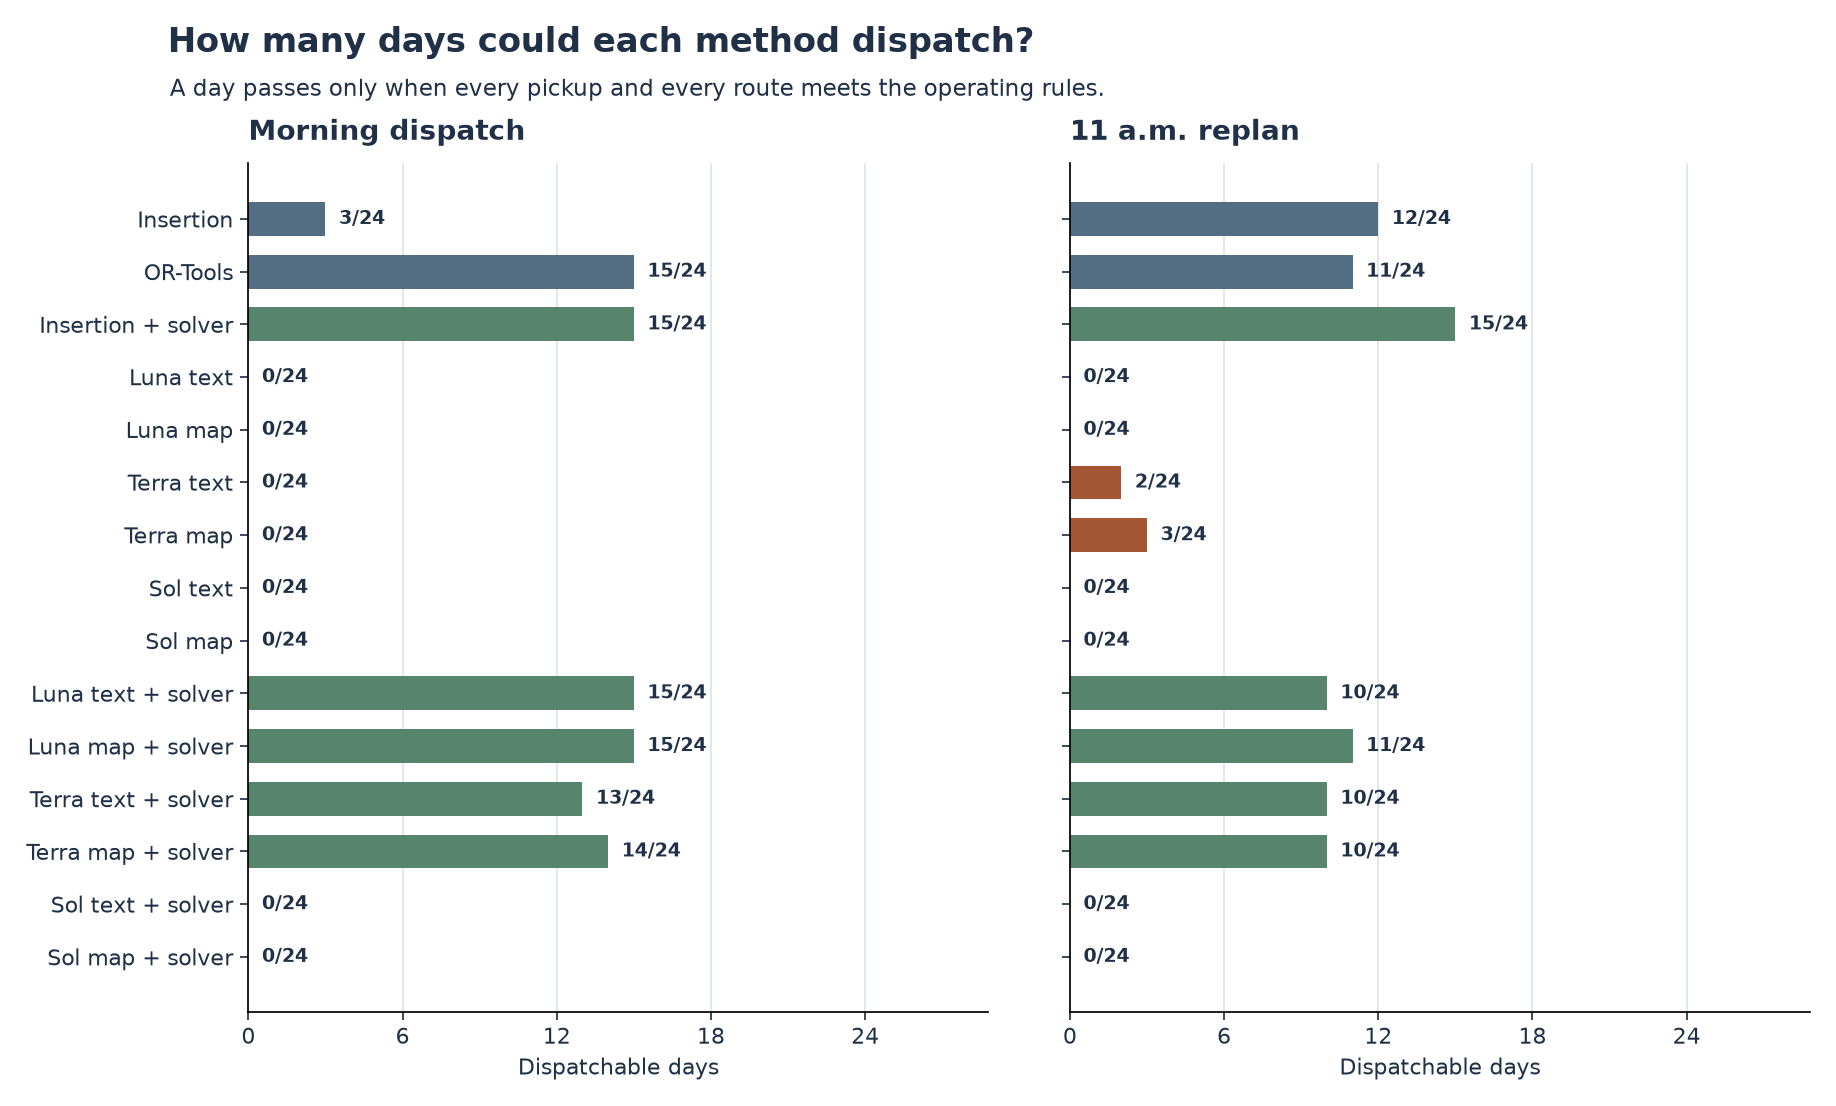

In [10]:
display(Image(filename='figures/dispatchable_days.png'))

The day counts make it clear where the comparison sits near a floor. Luna returned 23/24 readable text drafts and 21/24 readable map drafts, with 0/48 dispatchable mornings. Terra returned 1/24 readable text drafts and 0/24 readable map drafts, with 0/48 dispatchable mornings. Sol returned 0/24 readable text drafts and 0/24 readable map drafts, with 0/48 dispatchable mornings. A count based on readable routes alone answers whether those drafted routes held up. The all-day count also includes attempts in which dispatch never received a route list.

#### Morning dispatch

| Method | Dispatchable | Readable but invalid | Unreadable / timeout / error | Pass on readable | Pickup coverage | Coverage on readable | Median seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Insertion | 3/24 | 21 | n/a | 3/24 | 98.0% | 98.0% | 0.2 |
| OR-Tools | 15/24 | 0 | 9 no plan | 15/15 | 62.5% | 100.0% | 150.0 |
| Insertion + solver | 15/24 | 0 | 9 no plan | 15/15 | 62.5% | 100.0% | 150.0 |
| Luna text | 0/24 | 23 | 1 / 0 / 0 | 0/23 | 4.8% | 5.0% | 14.9 |
| Luna map | 0/24 | 21 | 3 / 0 / 0 | 0/21 | 5.8% | 6.6% | 16.3 |
| Terra text | 0/24 | 1 | 20 / 3 / 0 | 0/1 | 3.8% | 90.4% | 23.8 |
| Terra map | 0/24 | 0 | 23 / 1 / 0 | n/a | 0.0% | n/a | 7.8 |
| Sol text | 0/24 | 0 | 0 / 24 / 0 | n/a | 0.0% | n/a | 151.4 |
| Sol map | 0/24 | 0 | 0 / 24 / 0 | n/a | 0.0% | n/a | 151.4 |
| Luna text + solver | 15/24 | 0 | 9 no plan | 15/15 | 62.5% | 100.0% | 150.0 |
| Luna map + solver | 15/24 | 0 | 9 no plan | 15/15 | 62.5% | 100.0% | 150.0 |
| Terra text + solver | 13/24 | 0 | 11 no plan | 13/13 | 54.2% | 100.0% | 150.0 |
| Terra map + solver | 14/24 | 0 | 10 no plan | 14/14 | 58.3% | 100.0% | 150.0 |
| Sol text + solver | 0/24 | 0 | 24 no plan | n/a | 0.0% | n/a | 151.4 |
| Sol map + solver | 0/24 | 0 | 24 no plan | n/a | 0.0% | n/a | 151.4 |

Morning OR-Tools found a dispatchable plan on 15/24 days. Insertion alone passed 3/24, and insertion followed by the solver passed 15/24. An empty optimizer result is shown in the no-plan column. A partial, readable insertion plan appears under invalid. The distinction matters when choosing whether to start from a cheap proposed plan or to start the search empty.

#### 11 a.m. replan

| Method | Dispatchable | Readable but invalid | Unreadable / timeout / error | Pass on readable | Pickup coverage | Coverage on readable | Median seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Insertion | 12/24 | 12 | n/a | 12/24 | 99.1% | 99.1% | 0.0 |
| OR-Tools | 11/24 | 0 | 13 no plan | 11/11 | 45.7% | 100.0% | 0.4 |
| Insertion + solver | 15/24 | 0 | 9 no plan | 15/15 | 62.4% | 100.0% | 120.0 |
| Luna text | 0/24 | 20 | 2 / 2 / 0 | 0/20 | 30.4% | 36.6% | 22.7 |
| Luna map | 0/24 | 18 | 5 / 1 / 0 | 0/18 | 26.5% | 35.4% | 24.3 |
| Terra text | 2/24 | 15 | 0 / 7 / 0 | 2/17 | 68.4% | 96.5% | 103.6 |
| Terra map | 3/24 | 16 | 1 / 4 / 0 | 3/19 | 75.9% | 95.9% | 91.0 |
| Sol text | 0/24 | 0 | 0 / 24 / 0 | n/a | 0.0% | n/a | 121.4 |
| Sol map | 0/24 | 0 | 0 / 24 / 0 | n/a | 0.0% | n/a | 121.4 |
| Luna text + solver | 10/24 | 0 | 14 no plan | 10/10 | 41.6% | 100.0% | 120.0 |
| Luna map + solver | 11/24 | 0 | 13 no plan | 11/11 | 45.7% | 100.0% | 120.0 |
| Terra text + solver | 10/24 | 0 | 14 no plan | 10/10 | 41.5% | 100.0% | 120.0 |
| Terra map + solver | 10/24 | 0 | 14 no plan | 10/10 | 41.6% | 100.0% | 120.0 |
| Sol text + solver | 0/24 | 0 | 24 no plan | n/a | 0.0% | n/a | 121.4 |
| Sol map + solver | 0/24 | 0 | 24 no plan | n/a | 0.0% | n/a | 121.4 |

At the interruption, the unseeded solver passed 11/24 and insertion followed by the solver passed 15/24. All stage comparisons get the same 11 a.m. state. The model's morning failure cannot affect its replan score. The two stages differ in the size of the remaining problem and in the committed work already aboard.

### How much of the work was covered?

The figure gives each readable direct plan one point. It plots the percentage of pending pickups that pass the local checks, with a small line for the median. A solver can use the entire cost matrix. The model must work from the exact legs quoted in the prompt and the optional bounded lookup. The points are useful for comparing two readable plans even when both fail as full dispatches.

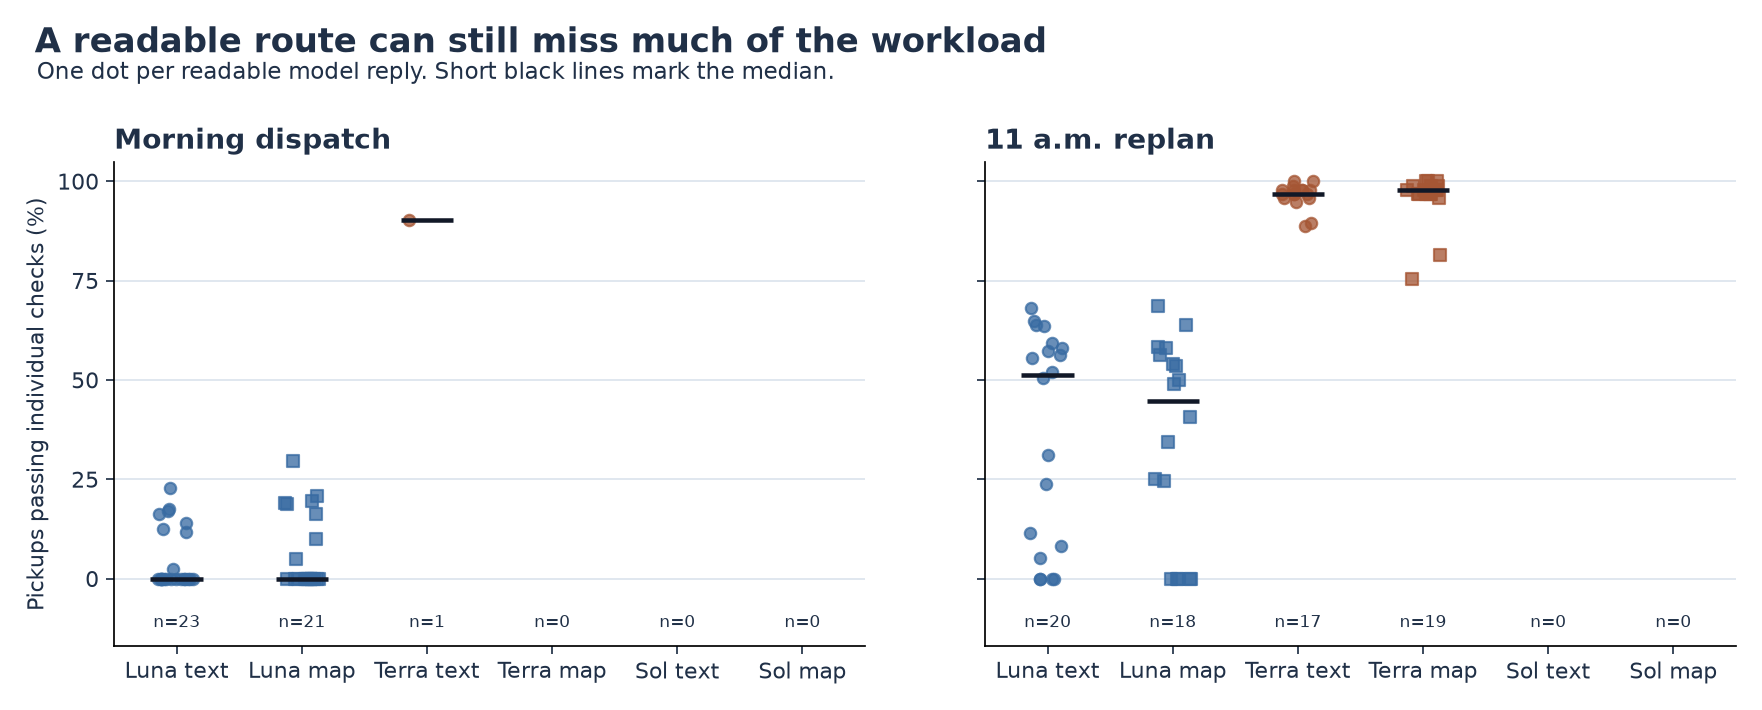

In [11]:
display(Image(filename='figures/pickup_coverage.png'))

The number of plotted replies differs because the models submit plans at different rates. For instance, a single readable draft can have a high coverage percentage while dozens of days still give dispatch nothing to work with. For operational comparisons use the all-day rate in the previous tables as well as the point distributions here.

### Did the map improve a paired attempt?

For each day and model we subtract the number of individually passing pickups in the text condition from the number in the map condition. The all-day comparison assigns zero passing pickups to replies that supply no plan. The last two columns repeat the comparison on case pairs with two readable plans. Positive differences favour maps.

| Stage | Model | Readable pairs | Map wins / ties / text wins (all) | Median additional stops (all) | Map wins / text wins (readable) | Median additional stops (readable) |
| --- | --- | --- | --- | --- | --- | --- |
| Morning dispatch | Luna | 20 | 6 / 11 / 7 | +0.00 | 6 / 6 | +0.00 |
| Morning dispatch | Terra | 0 | 0 / 23 / 1 | +0.00 | 0 / 0 | n/a |
| Morning dispatch | Sol | 0 | 0 / 24 / 0 | +0.00 | 0 / 0 | n/a |
| 11 a.m. replan | Luna | 17 | 7 / 6 / 11 | +0.00 | 7 / 8 | +0.00 |
| 11 a.m. replan | Terra | 12 | 13 / 3 / 8 | +1.00 | 6 / 3 | +0.50 |
| 11 a.m. replan | Sol | 0 | 0 / 24 / 0 | +0.00 | 0 / 0 | n/a |

Use both halves of the table. The map can change whether the model attempts to solve the case as well as what it writes. When many attempts tie at zero or few pairs have two readable plans, the comparison says little about map-assisted stop ordering. Small differences in full-plan counts are descriptive for this address panel and workload mix.

### What did the solver do with the available time?

On days where the configured unseeded solver found a plan, its median time to its first complete plan was 0.18 seconds in the morning and 0.06 seconds at 11 a.m. That first plan is the point at which dispatch could act. The solver often spends the rest of the 150 or 120 seconds searching for a cheaper valid list. The median time columns in the tables refer to when each process finishes.

The next table uses only days when both methods returned a dispatchable plan. The percentage difference compares operating costs on the same day. Negative values mean less cost. The saved table also reports changes in kilometres, driver hours and vehicles. [Paired operating measures](data/paired_cost.csv)

| Method | Morning paired | Cheaper | Median cost | 11 a.m. paired | Cheaper | Median cost |
| --- | --- | --- | --- | --- | --- | --- |
| Insertion | 3 | 0 | +33.89% | 8 | 0 | +11.13% |
| Insertion + solver | 15 | 1 | +0.00% | 11 | 4 | +0.00% |
| Luna text + solver | 15 | 0 | +0.00% | 10 | 0 | +0.00% |
| Luna map + solver | 15 | 0 | +0.00% | 11 | 0 | +0.00% |
| Terra text + solver | 13 | 0 | +0.02% | 9 | 0 | +0.75% |
| Terra map + solver | 14 | 0 | +0.00% | 9 | 1 | +0.37% |
| Sol text + solver | 0 | 0 | n/a | 0 | 0 | n/a |
| Sol map + solver | 0 | 0 | n/a | 0 | 0 | n/a |

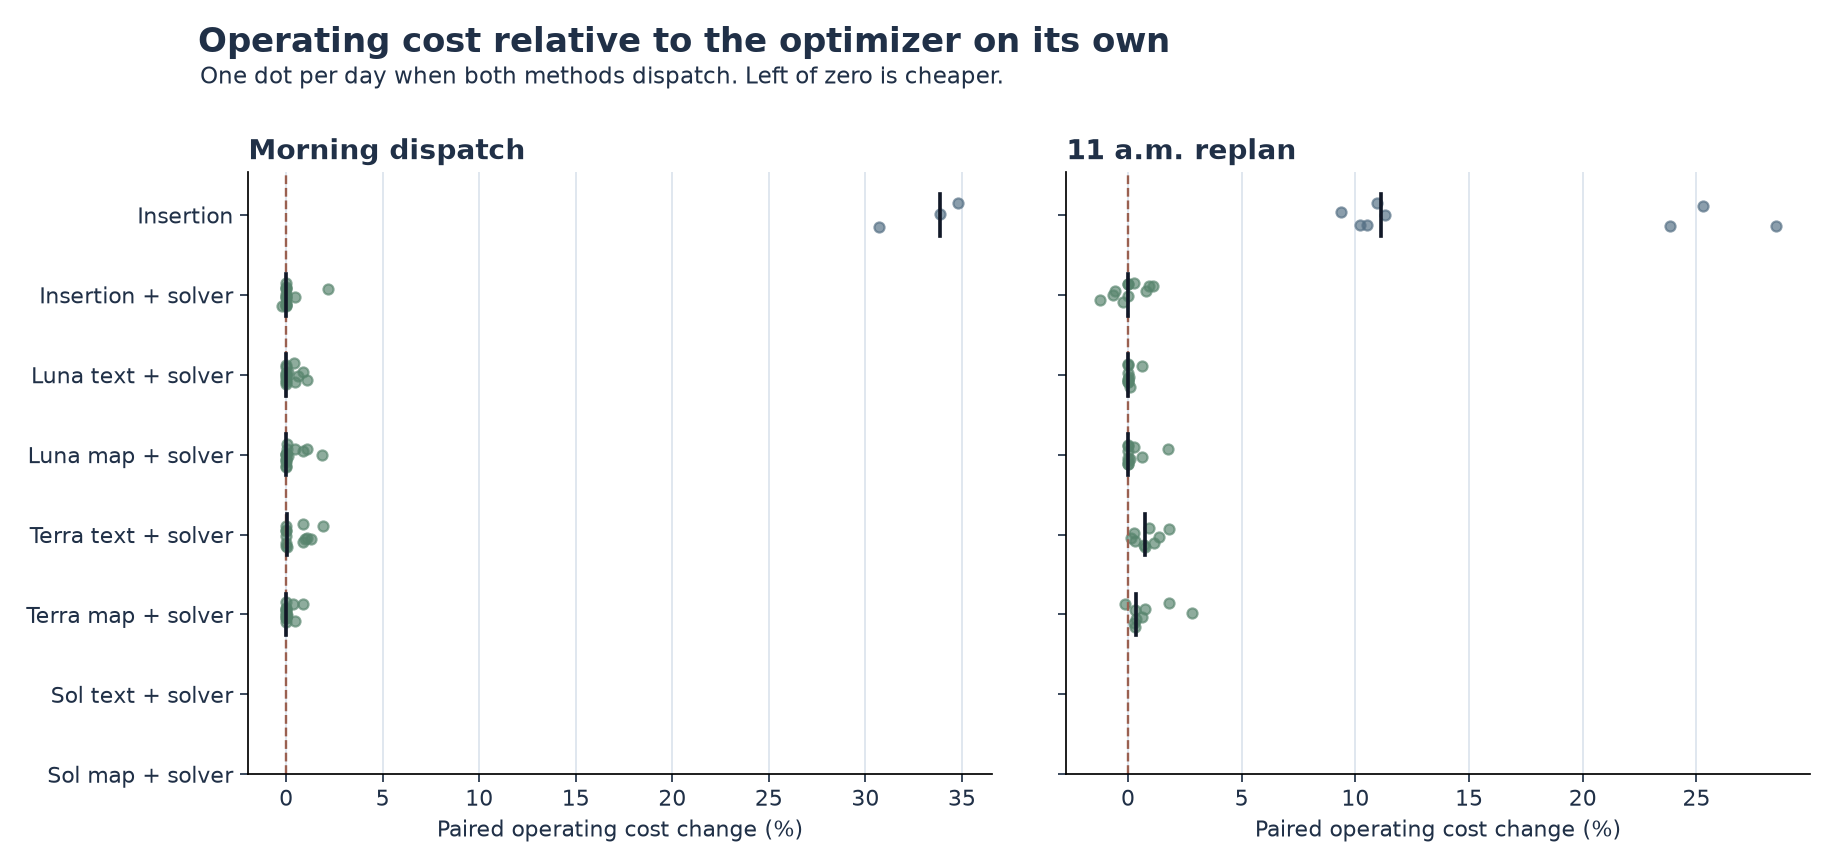

In [12]:
display(Image(filename='figures/operating_cost.png'))

For morning dispatch, median hybrid cost changes range from +0.00% (Luna text + solver, 15 paired days) to +0.02% (Terra text + solver, 13 paired days). For 11 a.m. replan, median hybrid cost changes range from +0.00% (Luna text + solver, 10 paired days) to +0.75% (Terra text + solver, 9 paired days). A fallback gives the same optimizer fewer seconds to work, so an identical plan is possible and a weaker plan can reflect the lost search time. An accepted seed can instead change the part of the search space the optimizer starts in. Seed and fallback counts separate these mechanisms.

The solver accepted 5 model drafts. Across all stage and model arms, 169 conditions used a cold fallback with time left. The remaining timeouts could not run a fallback. [Seed and fallback counts by condition](data/summary.csv)

The configured optimizer starts with parallel cheapest insertion, then tries to improve the complete route it finds. In a supplemental check after freezing the experiment, the same solver with local cheapest insertion produced 10/24 mornings and 12/24 replans in two seconds. That included 1 mornings and 1 replans missed by the originally configured search. The short diagnostic shows why the precise initialization matters. The primary comparison keeps the originally configured search and timing.

### What changed for drivers?

The replan has three incident pickups per day, for 72 across the 24 days. The incident total counts each affected pickup if it passes its individual checks, even on a day that fails overall. The driver-change and time columns use dispatchable days only. Paid minutes are compared with the old list under the old windows, so the difference can be negative when the new list saves time.

| Method | Dispatchable | Incident pickups on time | Median lists changed | Median extra paid minutes |
| --- | --- | --- | --- | --- |
| OR-Tools | 11/24 | 33/72 | 24 | -253.00 |
| Insertion + solver | 15/24 | 45/72 | 24 | -259.00 |
| Luna text + solver | 10/24 | 30/72 | 24 | -250.00 |
| Luna map + solver | 11/24 | 33/72 | 24 | -250.00 |
| Terra text + solver | 10/24 | 30/72 | 24 | -239.00 |
| Terra map + solver | 10/24 | 30/72 | 24 | -236.50 |
| Sol text + solver | 0/24 | 0/72 | n/a | n/a |
| Sol map + solver | 0/24 | 0/72 | n/a | n/a |
| Luna text | 0/24 | 21/72 | n/a | n/a |
| Luna map | 0/24 | 13/72 | n/a | n/a |
| Terra text | 2/24 | 50/72 | 23.5 | -15.50 |
| Terra map | 3/24 | 57/72 | 24 | -51.00 |
| Sol text | 0/24 | 0/72 | n/a | n/a |
| Sol map | 0/24 | 0/72 | n/a | n/a |

A separate simple repair used the old list and kept each incident pickup on its original truck. Trying earlier places in that list yielded 24/24 dispatchable replans, with a median of 3 changed driver lists and +14.5 extra paid minutes under the scenario objective. This method starts with information the primary arms did not receive. The test generator deliberately built incidents repairable by changing those orders. For this scenario, it supplies a practical reference and shows why retaining the old schedule can matter.

### Where the test was hardest

| Method | Morning ordinary | Morning tight | Morning scarce | 11 a.m. ordinary | 11 a.m. tight | 11 a.m. scarce |
| --- | --- | --- | --- | --- | --- | --- |
| Insertion | 3/8 | 0/8 | 0/8 | 8/8 | 3/8 | 1/8 |
| OR-Tools | 8/8 | 4/8 | 3/8 | 7/8 | 0/8 | 4/8 |
| Insertion + solver | 8/8 | 4/8 | 3/8 | 8/8 | 3/8 | 4/8 |
| Luna text | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 |
| Luna map | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 |
| Terra text | 0/8 | 0/8 | 0/8 | 1/8 | 0/8 | 1/8 |
| Terra map | 0/8 | 0/8 | 0/8 | 2/8 | 0/8 | 1/8 |
| Sol text | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 |
| Sol map | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 | 0/8 |

Each cell above is eight days. The same address panel is used across workloads. The specialist-capacity group has fewer easy ways to move refrigerated or palletized freight across trucks. The tight-window days reduce the tolerated margin for a wrong sequence. Some individual days look very different inside a group. The table helps keep an overall mean from hiding failures concentrated in those more constrained days.

## 5. Reading the plans that passed and failed

The main tables separate whether the model returned a route list from whether the proposed route would work. Across the full fleet conditions, the replies with no readable plan included timeout 114, declined to provide routes 45, other format 8, empty plan reply 2. A model that explains why it cannot confidently dispatch may be giving useful commentary to a person, but it leaves the requested route pending. A model that returns JSON can still create extra work for the same dispatcher. The table counts individual operating-rule violations in readable direct plans.

| Issue in readable plans | Morning records | 11 a.m. records |
| --- | --- | --- |
| extra copies | 2026 | 1023 |
| incompatible | 1729 | 279 |
| invalid departure | 54 | 49 |
| late return | 107 | 6 |
| late window | 3481 | 838 |
| missing pickups | 7753 | 1946 |
| over kg | 1529 | 280 |
| over litres | 1542 | 293 |
| over pallets | 1398 | 186 |
| unknown vehicle | 72 | 0 |

One late truck can produce a string of late stops, so these counts are records, not independent days. An overloaded vehicle may stay overloaded for several visits because every pickup adds freight until the depot. Read the violation table together with the day counts and the concrete fixes below.

### A morning list that arrived after closing on D01

Luna map returned a readable plan on **D01**. It served **71 of 240** pickups under the local checks and had 138 late visit records. This is one readable reply near the middle of the partial-coverage range we inspected. The vehicle below is one route from the parsed output.

```json
{"V05":[480,5,58,136,125,85,103,62,83,3,179,110]}
```

Pickup **110** at **105 Midwest Rd** takes 10 minutes to load. It must finish by 14:16. Assigned vehicle **V05** gets there at 14:18, begins loading at 14:18, and finishes at 14:28. It is 12 minutes too late. Counting the stop in the JSON proves only that the model listed it. Dispatch would need to move it earlier or find another vehicle with room and time. The checker records that timing failure even if the equipment and address are correct.

[Exact cache record for this reply](data/cache/b0fbc8489b6c5cc3cedf35b801cd20350e76e251042abfd968c2e50d6c7f2855.json)

### A text and map disagreement on D23

We selected the largest gap in individually valid pickups among case–model pairs that had two readable plans. On **D23** at 11 a.m. replan, **Luna map** served 66 of 96 pickups. **Luna text** served 0. Both received the same input row for stop **3** at **18 Wynford Dr**. Its hours were 11:47–14:10, loading took 8 minutes, and its permitted vehicle types were chill.

| Attempt | Replayed pickup outcome |
| --- | --- |
| Luna text | Omitted from scored visits |
| Luna map | V19 finished at 12:38 and V21 finished at 13:59 (incompatible) and V23 finished at 14:27 (late_window, over_kg, over_litres) |

This example shows what one partial-score difference can look like in a dispatch list. A label on the map cannot explain why the model made its choice. The paired results use all eligible days, including days that show the opposite direction and days when one response never supplied a plan.

### A readable message with no route list on D01

Terra map was asked to return the complete route object for morning dispatch. It returned this message in the response stream.

```text
{"error":"I cannot verify a feasible plan covering all 240 pickups with the provided travel data and constraints."}
```

This message can tell a dispatcher that the model wants more help. The response never assigns a vehicle or gives a stop order, so the route checker cannot score it. We recorded this as a declined plan, separate from an attempted route with violations. Treating it as a wrong stop order would overstate what the benchmark observed.

[Full request and record](data/cache/d302953ef78a9f6a6b06653698b656c113dda0de7230be6d3871b0bfc5cbdc28.json)

### A loading dock closes early on D01

The figure follows one driver's remaining pickup list. Gray bars show other loading appointments and the coloured bar shows the affected pickup. The dashed line is the new cutoff.

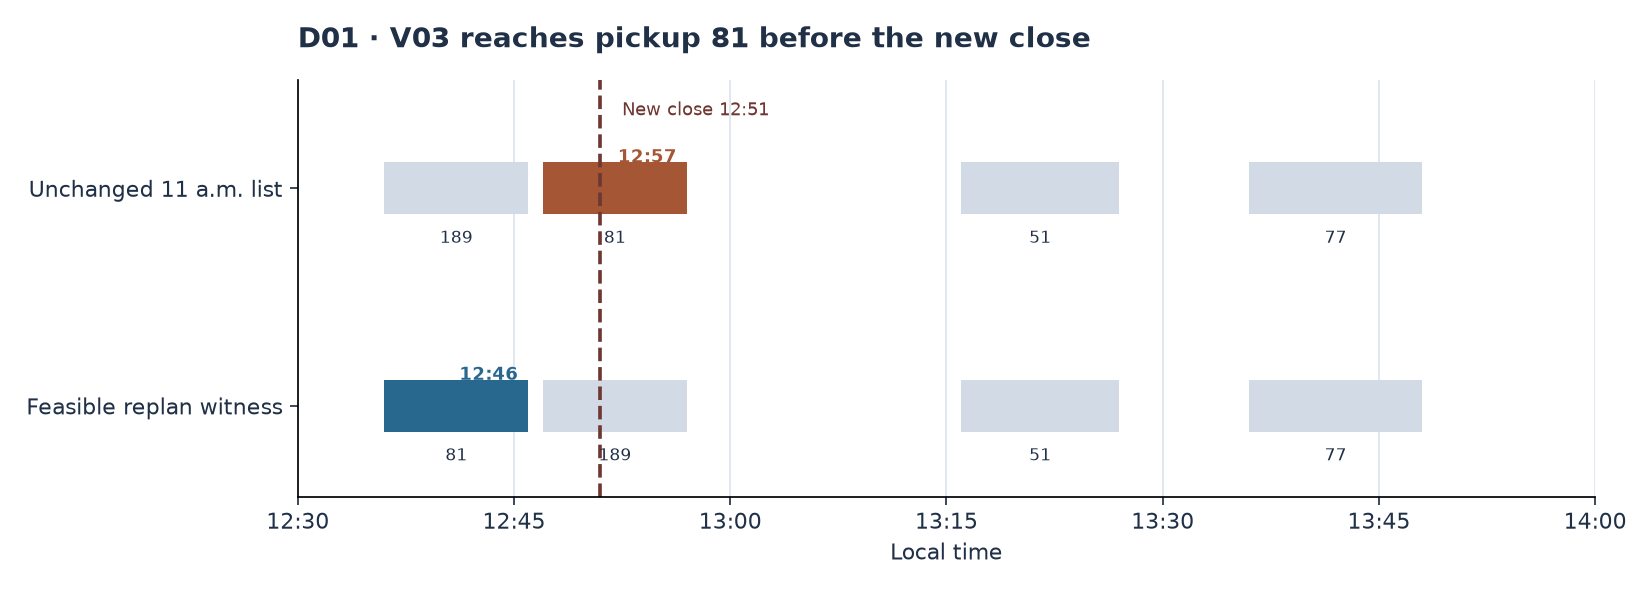

In [13]:
display(Image(filename='figures/replan_closing_time.png'))

On **D01**, pickup **81** at **3027 Islington Ave** originally closed at 14:16. At 11 a.m. it moved to 12:51. The shared reference would have completed loading at 12:57. The verifier's revised list completes it at 12:46. The vehicle is V03. At the point where it can take a new instruction, it has 330 kg, 2,790 L and 0 pallet positions already in use. Those quantities remain on board throughout the suffix. The plan changes stop order to preserve the pickup.

The revised order shown is the feasibility witness frozen with the test inputs. Moving the visit is enough for this truck. Other policies can hand it to a different compatible vehicle or choose another time, as long as the full replay passes. By design, each unchanged day misses exactly three revised deadlines.

In [14]:
from itertools import permutations


BLOCK_MODELS = MODELS
BLOCK_DEADLINE = 75


def make_block(case, sample_number, stage, seconds, meters):
    want = ("dry", "chill", "lift")[sample_number % 3]
    day = case[stage]
    if stage == "morning":
        options = [x for x in day["vehicles"] if x["kind"] == want]
        v = deepcopy(options[(sample_number // 3) % len(options)])
        departure, *route = day["witness"][v["id"]]
        split = len(route) // 2
        selected, handoff = route[:split], route[split]
        replay = evaluate(day["stops"], day["vehicles"], seconds, meters, day["witness"], details=True)
        required_by = replay["routes"][v["id"]]["stops"][split]["start"]
        v.update(close=required_by, ready=departure, end_position=handoff, active=True)
    else:
        affected = {e["stop"] for e in day["events"]}
        options = [x for x in day["vehicles"] if affected.intersection(day["unchanged"][x["id"]][1:])]
        preferred = [x for x in options if x["kind"] == want]
        pool = preferred or options
        v = deepcopy(pool[(sample_number // 3) % len(pool)])
        selected = day["unchanged"][v["id"]][1:]
        v["end_position"] = 0
    v["fixed_departure"] = v["ready"]
    stops = {j: day["stops"][j] for j in selected}
    plan_score_pairs = []
    for order in permutations(sorted(stops)):
        plan = {v["id"]: [v["ready"], *order]}
        result = evaluate(stops, [v], seconds, meters, plan)
        if result["feasible"]:
            plan_score_pairs.append((result["cost"], order, plan))
    if not plan_score_pairs:
        raise AssertionError(f"Known feasible block has no exhaustive solution: {case['id']}, {stage}")
    minimum, _, exact = min(plan_score_pairs)
    return {
        "case": case["id"], "stage": stage, "vehicle": v, "stops": stops, "labels": case["labels"],
        "best_plan": exact, "best_cost": minimum, "feasible_orders": len(plan_score_pairs),
        "enumerated_orders": math.factorial(len(stops)),
        "max_stop_leg_km": max((meters[v["profile"], a, b] for a in stops for b in stops), default=0) / 1000,
    }


def block_prompt(block, geography, seconds, meters):
    v = block["vehicle"]
    stops, labels = block["stops"], block["labels"]
    stage = "before the next appointment" if block["stage"] == "morning" else "after the 11:00 disruption"
    candidates = sorted(stops, key=labels.get)
    origin, end = v["position"], v["end_position"]
    p = v["profile"]
    X = list(dict.fromkeys([origin, *candidates, end]))
    table = ["|".join(map(str, [labels[j], geography[j]["address"], stops[j]["lo"], stops[j]["hi"],
                              stops[j]["service"], *stops[j]["load"], int(stops[j].get("urgent", False))]))
             for j in candidates]
    dist = ["from IDs to " + ",".join(str(labels[x]) for x in X)] + [
        f"{labels[a]}: " + " ".join(
            f"{leg_minutes(seconds, p, a, b)}/{int(meters[p, a, b])}" for b in X
        )
        for a in X
    ]
    return (
        f"Dispatch block {block['case']} {block['stage']}. Order the pickups for a single already assigned "
        f"vehicle {v['id']} {stage}. Its assigned jobs must stay on this truck. "
        f"Depart location {labels[origin]} at minute {v['ready']}; arrive at location {labels[end]} by "
        f"minute {v['close']}. The endpoint is an implicit handoff, not a pickup to list. "
        "All clock values are minutes since midnight. Drive, wait for a pickup to open, "
        "then finish its loading no later than its deadline. Pick up each of the jobs exactly once. "
        f"Load aboard at departure is {v['load']} (kg, litres, pallet positions). "
        f"The vehicle capacities in the same order are {v['caps']}. "
        f"Among feasible orders minimize the cost at {v['minute']} cents per paid minute "
        f"(departure through endpoint arrival) plus {v['km']} cents/km (round to the nearest cent per directed leg). "
        "Use the complete directional table below. You can answer directly from the table; "
        "do not use tools or ask for a lookup. "
        f'Output one JSON object in this form: {{"routes":{{"{v["id"]}":[{v["ready"]},'
        "pickup_id,pickup_id]}}. Replace the pickup_id placeholders with integers. "
        "Include only assigned pickup IDs after the fixed departure minute.\n\n"
        "Assigned pickups\nid|address|open|finish by|loading minutes|kg|litres|pallets|urgent\n"
        + "\n".join(table)
        + "\n\nComplete directional driving matrix. Cells are scheduled minutes/metres. Read rows as origins.\n"
        + "\n".join(dist)
    )


def collect_block(block, model, geography, seconds, meters, fresh=False):
    prompt = block_prompt(block, geography, seconds, meters)
    record = collect(prompt, model, None, CACHE, BLOCK_DEADLINE, fresh=fresh, effort=EFFORT,
                     session_id=f"blocks/{block['case']}/{block['stage']}/{model}")
    parsed = parse_answer(record["text"], block["labels"]) if record["status"] == "ok" else None
    status = record["status"]
    if status == "ok":
        status = "readable" if parsed and parsed[0] == "routes" else "unreadable"
    plan = parsed[1] if status == "readable" else None
    replay = evaluate(block["stops"], [block["vehicle"]], seconds, meters, plan) if plan is not None else None
    feasible = replay is not None and replay["feasible"]
    return {
        "case": block["case"], "stage": block["stage"], "model": model, "vehicle": block["vehicle"]["id"],
        "kind": block["vehicle"]["kind"], "jobs": len(block["stops"]), "status": status, "plan": plan,
        "feasible": feasible, "optimal": bool(feasible and replay["cost"] == block["best_cost"]),
        "cost": replay["cost"] if feasible else None, "best_cost": block["best_cost"],
        "served": replay["served"] if replay is not None else 0, "elapsed": record["elapsed"],
        "violations": replay["violations"] if replay is not None else {},
        "keys": [record["key"]], "usage_missing": int(not record["usage"]),
        **model_units([record]),
    }


def load_blocks(path):
    blocks = read_json_gz(path)
    for b in blocks:
        b["labels"] = {int(key): label for key, label in b["labels"].items()}
        b["stops"] = {int(key): stop for key, stop in b["stops"].items()}
    return blocks


def stitch_block_result(block, row, case, seconds, meters):
    """Substitute one validated block into its reference day or 11 a.m. suffix."""
    if not row["feasible"]:
        return {"stitched": False, "reference_cost_cents": None, "stitched_cost_cents": None}
    stage, v = block["stage"], block["vehicle"]
    task = case[stage]
    fleet_plan = deepcopy(task["witness"])
    existing = fleet_plan[v["id"]]
    replacement = row["plan"][v["id"]]
    if stage == "morning":
        fleet_plan[v["id"]] = [*replacement, *existing[len(replacement):]]
    else:
        fleet_plan[v["id"]] = replacement
    baseline = evaluate(task["stops"], task["vehicles"], seconds, meters, task["witness"])
    actual = evaluate(task["stops"], task["vehicles"], seconds, meters, fleet_plan)
    return {"stitched": actual["feasible"], "reference_cost_cents": baseline["cost"],
            "stitched_cost_cents": actual["cost"] if actual["feasible"] else None}


def score_stitching(blocks, block_rows, cases, seconds, meters):
    keys = {(b["case"], b["stage"]): b for b in blocks}
    source = {case["id"]: case for case in cases}
    return [
        {**row, **stitch_block_result(keys[row["case"], row["stage"]], row, source[row["case"]], seconds, meters)}
        for row in block_rows
    ]

In [15]:
def blocks_chart(rows):
    colors = {"gpt-6-luna": COLORS["luna"], "gpt-6.1-terra": COLORS["terra"],
              "gpt-6.2-sol": "#357975"}
    labels = {"gpt-6-luna": "Luna", "gpt-6.1-terra": "Terra", "gpt-6.2-sol": "Sol"}
    fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.8), sharey=True)
    fig.subplots_adjust(top=0.77, wspace=0.12)
    fig.suptitle("Single-truck blocks with feasible and minimum-cost orders",
                 x=0.09, y=0.98, ha="left", fontsize=15, weight="bold")
    fig.text(0.091, 0.895, "Hatched bars show feasible orders. Solid bars mark orders with the exact lowest cost.", fontsize=9.8)
    models = [m for m in MODELS if any(r["model"] == m for r in rows)]
    for stage, ax in zip(STAGES, axes):
        ax.set_title("Morning block" if stage == "morning" else "Afternoon block", loc="left")
        for i, model in enumerate(models):
            group = [r for r in rows if r["stage"] == stage and r["model"] == model]
            feasible = sum(r["feasible"] for r in group)
            optimum = sum(r["optimal"] for r in group)
            ax.barh(i - 0.14, feasible, height=0.23, color="white", edgecolor=colors[model], hatch="//")
            ax.barh(i + 0.14, optimum, height=0.23, color=colors[model])
            for offset, value in ((-0.14, feasible), (0.14, optimum)):
                ax.text(value + 0.27, i + offset, f"{value}/{len(group)}", va="center", fontsize=8)
        ax.set(xlim=(0, 14), yticks=range(len(models)), yticklabels=[labels[m] for m in models], xlabel="Blocks")
        ax.set_xticks(range(0, 13, 3))
        ax.grid(axis="x")
    axes[0].invert_yaxis()
    save_fig(fig, "single_truck_blocks.png")

In [16]:
full_blocks = load_blocks(DATA / "full_blocks.json.gz")
pilot_blocks = load_blocks(DATA / "pilot_blocks.json.gz")
for i, (case, saved) in enumerate(zip(cases, full_blocks)):
    rebuilt = make_block(case, i, saved["stage"], seconds, meters)
    assert rebuilt == saved, (case["id"], "block fixture mismatch")
block_rows = [collect_block(b, model, geography, seconds, meters)
              for b in full_blocks for model in BLOCK_MODELS]
block_rows = sorted(block_rows, key=lambda r: (r["case"], r["stage"], r["model"]))
assert block_rows == read_json_gz(DATA / "full_block_sessions.json.gz")
block_rows = score_stitching(full_blocks, block_rows, cases, seconds, meters)
pilot_block_rows = [collect_block(b, model, geography, seconds, meters)
                    for b in pilot_blocks for model in BLOCK_MODELS]
assert len(block_rows) == 72
save_metric_csv(block_rows, DATA / "block_results.csv")
blocks_chart(block_rows)
print(f"Verified the exact optimum and replayed each model answer on {len(full_blocks)} truck blocks.")

Verified the exact optimum and replayed each model answer on 24 truck blocks.


## 6. Sequencing one truck in one part of the day

A carrier can first assign jobs to a truck by area and period, then ask a planner to order the jobs inside each assignment. The first step still has to reserve enough refrigeration, box space and time across the fleet. For this follow-up we supplied the fixed assignments and tested the second step. That changes the task from dividing the whole day's work among 24 vehicles to visiting a small set of already assigned stops.

We selected one geographic and time block per held-out day, with 12 morning and 12 afternoon blocks. They contain 4–5 pickups. The median maximum directed road distance between jobs within a block is 14.0 km. The morning block starts at the depot and must reach a specific handoff before the next booking. The afternoon block starts from a truck's pending release point after 11 a.m., with its existing load, and finishes at the depot. Every planner gets the complete directed road table for the small block and uses the same fixed departure.

We checked every permutation of the assigned stops. Five stops have 5 × 4 × 3 × 2 × 1 = 120 possible orders. Any order that passes the checker is feasible. A feasible response earns the exact-minimum result if its operating cost equals the cheapest feasible order, including ties. That is a stronger quality reference than the whole-fleet study, where the search is time-limited.

| Model | Block | Cases | Feasible | Exact minimum | No readable plan | Median seconds |
| --- | --- | --- | --- | --- | --- | --- |
| Luna | Morning | 12 | 9 | 5 | 0 | 23.6 |
| Luna | Afternoon | 12 | 10 | 7 | 0 | 23.8 |
| Terra | Morning | 12 | 11 | 11 | 0 | 15.3 |
| Terra | Afternoon | 12 | 12 | 12 | 0 | 10.5 |
| Sol | Morning | 12 | 12 | 12 | 0 | 35.5 |
| Sol | Afternoon | 12 | 12 | 12 | 0 | 14.9 |

Luna found an exact minimum on 12/24 blocks and a feasible order on 19/24. Terra found an exact minimum on 23/24 blocks and a feasible order on 23/24. Sol found an exact minimum on 24/24 blocks and a feasible order on 24/24. Results combine the 12 morning and 12 afternoon blocks per model. The experiment changes both the size of the assignment and the road data available to the model. In this version each of the small blocks fits its whole distance table in one prompt.

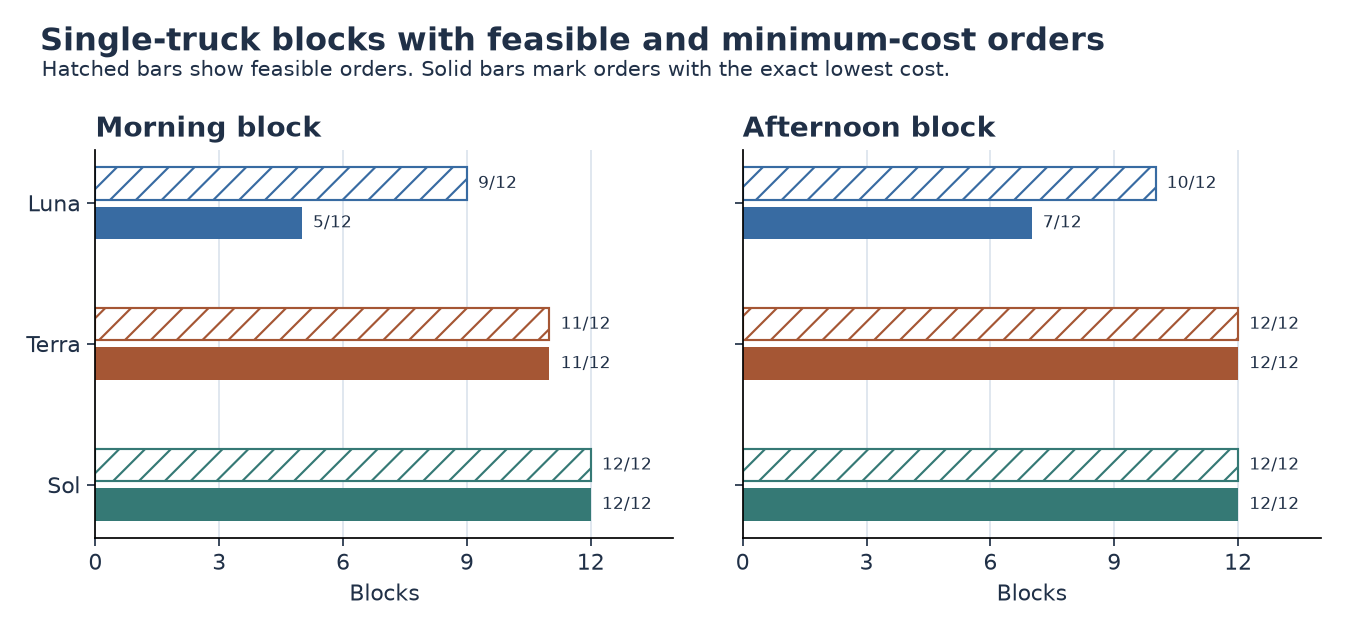

In [17]:
display(Image(filename='figures/single_truck_blocks.png'))

Solid bars count orders whose cost matches the verified minimum. The hatched bars include every feasible order. A gap between the bars means the method got the dispatch rules right and left some operating cost on the table.

### Worked single-truck block on D02, V01

The block begins at **708 Annette St** at 12:17, with 509 kg aboard, and must finish at **165 The Queensway** by 16:30. We counted 4 feasible orders among 24 permutations. The cheapest shown order is **51 → 196 → 1 → 97**. It reaches the endpoint at 13:55 at a scenario cost of CAD 64.67. Luna returned **51 → 196 → 1 → 97**, which matches the minimum cost.

| Pickup | Address | Opens | Must finish | Exact order starts | Exact order ends |
| --- | --- | --- | --- | --- | --- |
| 51 | 4906 Dundas St W | 12:08 | 12:40 | 12:27 | 12:33 |
| 196 | 1550 Jane St | 12:08 | 14:20 | 12:48 | 12:56 |
| 1 | 2179 Bloor St W | 12:08 | 13:25 | 13:10 | 13:19 |
| 97 | 196 Royal York Rd | 12:37 | 14:16 | 13:34 | 13:45 |

We substituted each feasible block back into the reference fleet plan, preserving the other driver lists. The independent checker accepted 66 of 66 replacements. This tests one substitution per day within its existing schedule. The bridge between blocks matters as much as finding a short order. A good morning ordering still has to hand the truck and its full load to the next part of its schedule at the agreed location and time. Errors in assigning the work to zones or capacity would affect the whole fleet even if each small order is optimal. Our upstream assignments come from a known feasible reference. The block scores do not measure whether a planner can create those assignments.

## 7. Limitations

The manifests reuse one Toronto address panel and follow the same morning and afternoon waves. Freight, access rules and time windows are simulated around a known schedule. Multiple depots, live requests or driver absences would expose other constraints.

Static road estimates omit observed traffic and depot queues. A [municipal restriction spot check](data/geography_sources.md) found a truck prohibition missing from the checked OpenStreetMap segment. Dispatchability here means the plan meets the modeled rules. Live dispatch would need current restriction and loading access checks.

The text and map conditions share the same bounded road lookup. The optimizer has the full matrix. This tests direct planning with that interface. A model writing and running a heuristic or translating dispatch notes into solver constraints is a different workflow.

At 11 a.m. almost every truck is already committed to its next stop. The assigned work and feasibility snapshots describe the end of those commitments. The experiment doesn't test a truck breakdown with cargo onboard. The old-list repair is particularly effective because the generator builds all three incidents so they can be repaired by moving stops within the current lists.

Paired cost compares only mutually feasible days. Whole-fleet solvers give time-limited results, and changing their first-plan strategy recovers some missed days. The small-block comparison checks exact costs on assigned jobs and includes a complete leg table. It measures stop ordering after assignment.

The original settings were fixed before the Luna and Terra held-out collection. Sol and the truck-block experiments came later at the owner's request. Sol used the newer Codex CLI. Time includes CLI execution and solver work. Prompt assembly, parsing, file writes and tracing sit outside it. [Protocol history](data/PROTOCOL.md)

## 8. How to reproduce

[The executed notebook](49_pickup_routing.ipynb) replays the responses offline, checks the routes and redraws the figures. Timed optimizer runs are saved as frozen plans.

Install the Python dependencies and run Jupyter from this experiment folder.

```bash
python -m pip install -r requirements.txt
python -m nbconvert --to notebook --execute --inplace 49_pickup_routing.ipynb
```

The notebook has switches for cache misses and local solver reruns. Fresh calls need the pinned Codex CLI and model access. Wall-clock search can produce different costs on replaying the solver. Each cache record stores the full request and reply, including the digest of any [map image](data/maps/).

- [Frozen city inputs and licences](data/geography_sources.md), [held-out dispatch cases](data/full_cases.json.gz), and [single-truck blocks](data/full_blocks.json.gz) contain the instances, reference plans and incident records.
- [Per-arm day scores](data/results.csv), [dispatch summary](data/summary.csv), [paired cost comparison](data/paired_cost.csv), and [map pairs](data/map_pairs.csv) contain the primary results.
- [Single-truck results](data/block_results.csv), [solver sensitivities](data/sensitivity_results.csv), and [unreadable reply audit](data/format_audit.csv) contain the follow-up evidence.
- [Individual model requests and replies](data/cache/), [timed comparison plans](data/full_solver.json.gz), and [run manifest](data/manifest.json) make the calculations traceable.

### Model usage and spend

| Batch | Sessions | CLI turns | Reported input tokens | Reported output tokens | Turns missing usage | Planning-rate estimate |
| --- | --- | --- | --- | --- | --- | --- |
| Fleet pilot | 24 | 35 | 462,653 | 29,485 | 5 | US$ 5.66 |
| Full fleet | 288 | 366 | 7,069,640 | 318,995 | 114 | US$ 81.86 |
| Truck-block pilot | 6 | 6 | 72,707 | 1,169 | 0 | US$ 0.77 |
| Full truck blocks | 72 | 72 | 880,505 | 38,227 | 0 | US$ 10.14 |

The scoped runs made 479 CLI turns. Reported usage totals **US$ 98.43** at the fixed planning rates of US$10 per million input tokens and US$35 per million output tokens. The CLI did not supply billed spend. Turns that supplied no usage contribute no known tokens, so the estimate leaves those tokens unknown. The eight prior Sol access errors are cached and are outside these scored sessions. Their provider responses included no usage.

In [18]:
scored_turns = (list(pilot_sessions.values()) + list(sessions.values()) +
                pilot_block_rows + block_rows)
total = sum(row["estimated_usd"] for row in scored_turns)
calls = sum(len(row["keys"]) for row in scored_turns)
missing = sum(row["usage_missing"] for row in scored_turns)
print(f"{calls} recorded CLI turns. Reported usage at planning rates: US$ {total:.2f}.")
print(f"Usage was missing on {missing} turns. The CLI reports no billed total.")

479 recorded CLI turns. Reported usage at planning rates: US$ 98.43.
Usage was missing on 119 turns. The CLI reports no billed total.


## 9. Future work and further reading

Links checked November 18, 2026.

### Future work

1. **Validate the vehicle assignment as well as sequencing.** Assign work by geography, time and equipment. Vary the jobs per block and check whole-fleet feasibility after stitching. The local results motivate testing the assignment step.
2. **Replan with yesterday's list and a bigger disruption.** Give planners the old lists and simulate a truck failure or new urgent orders. Measure service and changes to drivers' lists. The old-list repair shows why retaining those lists matters.
3. **Test a solver portfolio and explicit stability costs.** Compare several starting strategies and add a documented cost for changing a driver list. Record first feasible plan and final cost at equal deadlines. The alternate constructor recovered some primaries, and rebuilding from an empty suffix can send many drivers a changed list.
4. **Offer richer road data and dispatch notes.** Match the exact road data available to LLMs and solvers at each scale, and vary the road lookup budget or provide an independent constraint tool. Then test a separate LLM step that turns a note such as “forklift is down, send a liftgate” into a checkable constraint. The morning model outputs show that being willing to offer a plan and returning a correct plan are separate problems.

### Further reading

- [Algorithms for the Vehicle Routing and Scheduling Problems with Time Window Constraints](https://pubsonline.informs.org/doi/10.1287/opre.35.2.254) (Solomon, 1987). Introduces benchmark instances and insertion strategies for routes with customer time windows.
- [A Review of Dynamic Vehicle Routing Problems](https://www.cirrelt.ca/documentstravail/cirrelt-2011-62.pdf) (Pillac et al., 2011). The authors' working-paper version describes ways to revise routes as new information becomes available.
- [PyVRP: A High-Performance VRP Solver Package](https://arxiv.org/abs/2403.13795) (Wouda et al., 2024). A documented alternative search framework for studying time windows and routing quality.
- [2021 Amazon Last Mile Routing Research Challenge: Data Set](https://pubsonline.informs.org/doi/10.1287/trsc.2022.1173) (Merchán et al., 2022). Observed delivery routes provide a different setting for studying what schedules and road costs miss about real driver behavior.